In [1]:
import functools
import numpy as np
import pyleoclim as pyleo
import pickle
import h5py
import proplot as pplt
from scipy.interpolate import interp1d
import matplotlib.colors as mcolors
import sys
import os
import subprocess
import shutil
sys.path.append(os.path.dirname(os.getcwd()))   # add parent dir
from solar_forcing import import_orbital_parameters_v2

def day_to_rmon_ts_2d(ndays, rmonbeg, rmonend, yd_2d):
    nm  = 12
    nd  = int(ndays)
    pad = 30

    ydx = np.concatenate([yd_2d[:, -pad:], yd_2d, yd_2d[:, :pad]], axis=1)

    ibeg = np.ceil(rmonbeg).astype(int)
    iend = np.ceil(rmonend).astype(int)

    ym_adj = np.zeros((yd_2d.shape[0], nm))

    for m in range(nm):
        i0  = ibeg[m]
        i1  = iend[m]
        idx = np.arange(i0 + pad - 1, i1 + pad)
        wgt = np.ones(len(idx))
        wgt[0]  = abs(float(i0) - rmonbeg[m])
        wgt[-1] = 1.0 - abs(rmonend[m] - float(i1))
        ym_adj[:, m] = ydx[:, idx] @ wgt / wgt.sum()

    return ym_adj

def get_month_lengths(ecc, per, ecc0, per0):
    
    nm = 12
    nd_365 = 365
    veqday_365 = 80.5

    present_mon_365_progreg = np.array(
        [31.0, 28.2425, 31.0, 30.0, 31.0, 30.0, 31.0, 31.0, 30.0, 31.0, 30.0, 31.0])
    present_beg_365_progreg = np.array(
        [0.0, 31.0, 59.2425, 90.2425, 120.2425, 151.2425,
         181.2425, 212.2425, 243.2425, 273.2425, 304.2425, 334.2425])
    present_mid_365_progreg = np.array(
        [15.5, 45.1213, 74.7425, 105.2425, 135.7425, 166.2425,
         196.7425, 227.7425, 258.2425, 288.7425, 319.2425, 349.7425])
    present_end_365_progreg = np.array(
        [31.0, 59.2425, 90.2425, 120.2425, 151.2425, 181.2425,
         212.2425, 243.2425, 273.2425, 304.2425, 334.2425, 365.2425])

    yrlen  = 365.2422
    ndyr   = nd_365
    veqday = veqday_365
    imonlen = np.floor(present_mon_365_progreg).astype(int)

    # GISS 0ka orbital parameters (hardcoded from Bartlein table)
    eccen_0ka = ecc0
    perih_0ka = np.degrees(per0)
    rmonlen_0ka, rmonbeg_0ka, rmonmid_0ka, rmonend_0ka = monlen(
        yrlen, ndyr, veqday, imonlen, eccen_0ka, perih_0ka)

    # GISS 6ka orbital parameters (hardcoded from Bartlein table)
    # swap these out for other ages as needed
    #orb = import_orbital_parameters_v2(ageBP)
    eccen = ecc
    perih = np.degrees(per)
    rmonlen, rmonbeg, rmonmid, rmonend = monlen(
        yrlen, ndyr, veqday, imonlen, eccen, perih)

    # adjust to 0ka reference
    #rmonlen = adjust_to_ref_length(rmonlen, rmonlen_0ka, present_mon_365_progreg)
    #rmonbeg = adjust_to_ref_day(rmonbeg, rmonbeg_0ka, present_beg_365_progreg)
    #rmonmid = adjust_to_ref_day(rmonmid, rmonmid_0ka, present_mid_365_progreg)
    #rmonend = adjust_to_ref_day(rmonend, rmonend_0ka, present_end_365_progreg)
    #rmonlen_ratio = rmonlen / present_mon_365_progreg

    
    rmonbeg = adjust_to_ref_day(rmonbeg, rmonbeg_0ka, present_beg_365_progreg)
    rmonmid = adjust_to_ref_day(rmonmid, rmonmid_0ka, present_mid_365_progreg)
    rmonend = adjust_to_ref_day(rmonend, rmonend_0ka, present_end_365_progreg)

    # derive rmonlen from adjusted begin-days so it conserves the year exactly
    yrlen = 365.2422
    rb_ext  = np.concatenate([rmonbeg, [rmonbeg[0] + yrlen]])
    rmonlen = np.diff(rb_ext)
    rmonlen_ratio = rmonlen / present_mon_365_progreg

    return rmonlen, rmonbeg, rmonmid, rmonend, rmonlen_ratio

def monlen(yrlen, ndyr, veqday, imonlen, eccen, perih):
    
    '''
    calculate month lengths, and beginning, middle and ending day times for a particular orbital configuration, 
    calendar and vernal equinox day using a "traverse-time/time-of-flight" expression based on Kepler's equation:
    (Curtis, H.D. (2014) Orbital Mechanics for Engineering Students, Elsevier, Ch. 3)
    
    Input:
        
        yrlen            -- total length of year (days)
        ndyr             -- number of days in year
        veqday           -- real vernal equinox day
        imonlen(nm)      -- number of days in each month at present (calendar dependent)
        eccen, perih     -- orbital parameters
        
    Output:
        
        rmonlen(nm)     -- real month lengths
        rmonbeg(nm)     -- real month beginning day
        rmonmid(nm)     -- real month middle day
        rmonend(nm)     -- real month ending day
        
    Single-use:
        
        tt_VE_to_SS     -- traverse time, VE to SS
        tt_SS_to_AE     -- traverse time, SS to AE    
        tt_AE_to_WS     -- traverse time, AE to WS
        tt_WS_to_VE     -- traverse time, WS to VE
        
            
        angle_VE_to_Jan1     -- angle between vernal equinox and Jan 1
        tt_perih_to_VE       -  traverse time, perihelion to vernal equinox
        angle_perih_to_Jan1  -- angle, perihelion to Jan 1
        angle_perih_to_VE    -- angle, perihelion to vernal (March) equinox
        angle_perih_to_SS    -- angle, perihelion to summer (June) solstice
        angle_perih_to_AE    -- angle, perihelion to autumn (September) equinox
        angle_perih_to_WS    -- angle, perihelion to winter (December) solstice
        tt_perih_to_SS       -- traverse time, perihelion to summer solstice
        tt_perih_to_AE       -- traverse time, perihelion to autumn equinox
        tt_perih_to_WS       -- traverse time, perihelion to winter solstice
   
        mon_angle(nm)        -- month angle (degrees)
        beg_angle(nm), mid_angle(nm), end_angle(nm) -- beginning, middle and end of month, relative to Jan 1
        
        angles and traverse times for beginning, middle and ending days of each month
        -----------------------------------------------------------------------------
        perih_angle_month_beg(nm), tt_month_beg(nm), t_month_beg(nm)
        perih_angle_month_mid(nm), tt_month_mid(nm), t_month_mid(nm)
        perih_angle_month_end(nm), tt_month_end(nm), t_month_end(nm)
   
    '''
    nm = len(imonlen)
    rmonlen = np.zeros(nm)
    rmonbeg = np.zeros(nm)
    rmonmid = np.zeros(nm)
    rmonend = np.zeros(nm)
    mon_angle = np.zeros(nm)
    beg_angle = np.zeros(nm)
    mid_angle = np.zeros(nm)
    end_angle = np.zeros(nm)
    perih_angle_month_beg = np.zeros(nm)
    perih_angle_month_mid = np.zeros(nm)
    perih_angle_month_end = np.zeros(nm) 
    tt_month_beg = np.zeros(nm)
    tt_month_mid = np.zeros(nm)
    tt_month_end = np.zeros(nm)
    t_month_beg = np.zeros(nm)
    t_month_mid = np.zeros(nm)
    t_month_end = np.zeros(nm)

    
    
    
    
    DEBUG_WRITE = False
    
    import math
    pi = math.pi
    
    
    # number of days in year
    if DEBUG_WRITE:
        print(f"number of days in year: {ndyr}")
        
    # perihelion (perihelion longitude = longitude of vernal equinox + 180 degrees, by definition)
    if DEBUG_WRITE:
        print(f"perihelion: {perih}")
        
    # angle and traverse time, perihelion to vernal equinox 
    angle_perih_to_VE = 360.00 - perih
    if DEBUG_WRITE:
        print(f"angle_perih_to_VE: {angle_perih_to_VE}")
        
    # traverse time (along elliptical orbit) perihelion to vernal equinox
    tt_perih_to_VE = kepler_time(eccen, yrlen, angle_perih_to_VE)
    if DEBUG_WRITE:
        print(f"tt_perih_to_VE: {tt_perih_to_VE}")
     
    # angle, perihelion to Jan1
    angle_perih_to_Jan1 = angle_perih_to_VE - veqday * (360.0/yrlen)
    if DEBUG_WRITE:
        print(f"angle_perih_to_Jan1: {angle_perih_to_Jan1}")
        
    # angle, vernal equinox to Jan1 (Jan 1 begins at 0.0 (or 360.0 degrees))
    angle_VE_to_Jan1 = 360.0 - veqday * (360.0/yrlen)
    if DEBUG_WRITE:
        print(f"angle_VE_to_Jan1: {angle_VE_to_Jan1}")
    
    # angle, perihelion to SS
    angle_perih_to_SS = angle_perih_to_VE + 90.0
    if DEBUG_WRITE:
        print(f"angle_perih_to_SS: {angle_perih_to_SS}")
        
    
    # traverse time (along elliptical orbit) perihelion to SS
    tt_perih_to_SS = kepler_time(eccen, yrlen, angle_perih_to_SS)
    if DEBUG_WRITE:
        print(f"tt_perih_to_SS: {tt_perih_to_SS}")

    # traverse time (along elliptical orbit) VE to SS
    tt_VE_to_SS = tt_perih_to_SS - tt_perih_to_VE
    if abs(tt_VE_to_SS) > 180.0:
        tt_VE_to_SS = yrlen - abs(tt_VE_to_SS)
    if DEBUG_WRITE:
        print(f"tt_VE_to_SS: {tt_VE_to_SS}, {angle_perih_to_SS - angle_perih_to_VE}")
        
    # angle, perihelion to AE
    angle_perih_to_AE = angle_perih_to_VE + 180.0
    if DEBUG_WRITE:
        print(f"angle_perih_to_AE: {angle_perih_to_AE}")
        
        
    # traverse time (along elliptical orbit) perihelion to AE
    tt_perih_to_AE = kepler_time(eccen, yrlen, angle_perih_to_AE)
    if DEBUG_WRITE:
        print(f"tt_perih_to_AE: {tt_perih_to_AE}")
     
    # traverse time (along elliptical orbit) SS to AE
    tt_SS_to_AE = tt_perih_to_AE - tt_perih_to_SS
    if abs(tt_SS_to_AE) > 180.0:
        tt_SS_to_AE = yrlen - abs(tt_SS_to_AE)
    if DEBUG_WRITE:
        print(f"tt_SS_to_AE: {tt_SS_to_AE}, {angle_perih_to_AE-angle_perih_to_SS}")
        
    # angle, perihelion to WS
    angle_perih_to_WS = angle_perih_to_VE + 270.0
    if DEBUG_WRITE:
        print(f"angle_perih_to_WS: {angle_perih_to_WS}")
        
    
    # traverse time (along elliptical orbit) perihelion to WS
    tt_perih_to_WS = kepler_time(eccen, yrlen, angle_perih_to_WS)
    if DEBUG_WRITE:
        print(f"tt_perih_to_WS: {tt_perih_to_WS}")
        
    # traverse time (along elliptical orbit) AE to WS
    tt_AE_to_WS = tt_perih_to_WS - tt_perih_to_AE
    if abs(tt_AE_to_WS) > 180.0:
        tt_AE_to_WS = yrlen - abs(tt_AE_to_WS)
    if DEBUG_WRITE:
        print(f"tt_AE_to_WS: {tt_AE_to_WS}, {angle_perih_to_WS-angle_perih_to_AE}")
         
    # traverse time (along elliptical orbit) perihelion to VE
    if DEBUG_WRITE:
        print(f"tt_perih_to_VE: {tt_perih_to_VE}")
        
    #  traverse time (along elliptical orbit) WS to VE
    tt_WS_to_VE = tt_perih_to_VE - tt_perih_to_WS
    if abs(tt_WS_to_VE) > 180.0:
        tt_WS_to_VE = yrlen - abs(tt_WS_to_VE) 
    if DEBUG_WRITE:
        print(f"tt_WS_to_VE: {tt_WS_to_VE}, {angle_perih_to_VE-angle_perih_to_WS}")
        
    if DEBUG_WRITE:
        print(f'("check: "{tt_VE_to_SS + tt_SS_to_AE + tt_AE_to_WS + tt_WS_to_VE}')
         
    # angles, traverse times, month lengths, etc. for individual months

    # month angle (and beginning, middle and end of month, relative to Jan1)
    if DEBUG_WRITE:
        print()
    mon_angle[0] = int(imonlen[0]) * (360.0 / yrlen)
    beg_angle[0] = 0.0
    mid_angle[0] = beg_angle[0] + mon_angle[0] / 2.0
    end_angle[0] = mon_angle[0]

    for m in range(1, nm):
        mon_angle[m] = int(imonlen[m]) * (360.0 / yrlen)
        beg_angle[m] = beg_angle[m - 1] + mon_angle[m - 1]
        mid_angle[m] = beg_angle[m] + mon_angle[m] / 2.0
        end_angle[m] = beg_angle[m] + mon_angle[m]

    if DEBUG_WRITE:
        for m in range(nm):
            print(
                f"{m+1:4d}"
                f"{float(imonlen[m]):9.4f}"
                f"{mon_angle[m]:9.4f}"
                f"{beg_angle[m]:9.4f}"
                f"{mid_angle[m]:9.4f}"
                f"{end_angle[m]:9.4f}"
            )
            
    # angles from perihelion etc. for month beginning, mid, and ending days
    
    for m in range(0, nm):
    
        # angle from perihelion for each month's beginning, middle and ending days (on circular orbit)
        perih_angle_month_beg[m] = angle_perih_to_Jan1 + beg_angle[m] 
        perih_angle_month_mid[m] = angle_perih_to_Jan1 + mid_angle[m] 
        perih_angle_month_end[m] = angle_perih_to_Jan1 + end_angle[m]  
    
        # traverse times from perihelion for each month's beginning, middle and ending days (on elliptical orbit)
        tt_month_beg[m] = kepler_time(eccen, yrlen, perih_angle_month_beg[m])
        tt_month_mid[m] = kepler_time(eccen, yrlen, perih_angle_month_mid[m])
        tt_month_end[m] = kepler_time(eccen, yrlen, perih_angle_month_end[m])
    
        # traverse time from vernal equinox for each month's beginning, middle and ending days (on elliptical orbit)
        t_month_beg[m] = tt_month_beg[m] - tt_perih_to_VE
        t_month_mid[m] = tt_month_mid[m] - tt_perih_to_VE
        t_month_end[m] = tt_month_end[m] - tt_perih_to_VE
    
        # beginning, middle and ending days of each month (relative to Jan1)
        rmonbeg[m] = math.fmod(t_month_beg[m] + veqday, yrlen)
        if perih_angle_month_beg[m] > 360.0:
            t_month_beg[m] += yrlen
            rmonbeg[m] += yrlen

        rmonmid[m] = math.fmod(t_month_mid[m] + veqday, yrlen)
        if perih_angle_month_mid[m] > 360.0:
            t_month_mid[m] += yrlen
            rmonmid[m] += yrlen

        rmonend[m] = math.fmod(t_month_end[m] + veqday, yrlen)
        if perih_angle_month_end[m] > 360.0:
            t_month_end[m] += yrlen
            rmonend[m] += yrlen
            
            
    # fixup for ending day of last month (when end of last month appers in beginning of year)
    if rmonend[nm-1] < 30.0:
        rmonend[nm-1]= rmonend[nm-1] + yrlen 
        
    if DEBUG_WRITE:
        for m in range(0, nm):
            print(f'm: {m}, perih_angle_month_beg: {perih_angle_month_beg[m]}, tt_month_beg: {tt_month_beg[m]},  t_month_beg: {t_month_beg[m]}, beg_day: {rmonbeg[m]}')
        for m in range(0, nm):
            print(f'm: {m}, perih_angle_month_mid: {perih_angle_month_mid[m]}, tt_month_mid: {tt_month_mid[m]},  t_month_beg: {t_month_mid[m]}, mid_day: {rmonmid[m]}')    
        for m in range(0, nm):
            print(f'm: {m}, perih_angle_month_end: {perih_angle_month_end[m]}, tt_month_end: {tt_month_mid[m]},  t_month_beg: {t_month_end[m]}, end_day: {rmonend[m]}')    


    # month length (month beginning to next month beginning)
    
    # month length (month beginning to next month beginning)
    for m in range(0, nm-1):          # was nm-2, missing last two months
        rmonlen[m] = t_month_beg[m+1] - t_month_beg[m]
        if rmonlen[m] <= 0.0:
            rmonlen[m] += yrlen
            
    rmonlen[nm-1] = t_month_beg[0] - t_month_beg[nm-1]
    if rmonlen[nm-1] <= 0.0:
        rmonlen[nm-1] += yrlen
        

    
    return rmonlen, rmonbeg, rmonmid, rmonend

def kepler_time(eccen, T, theta_deg):
    
    # travel time along orbit relative to periapsis/perihelion (i.e. 0.0 at perihelion)
    
    # input:  
    #   eccen         --   eccentricity
    #   T             --   orbital period (yrlen)
    #   theta_deg     --   "true" anomaly (angle from perihelion (degrees)
        

   #  output:  
   #    time          --   traverse time since perihelion (time, same units as T)
   
   # (Curtis, H.D. (2014) Orbital Mechanics for Engineering Students, Elsevier, Ch. 3)
   
   # converted to python from fortran code of PaleoCalAdjust -- PJ Bartlein
   
   import math
   pi = math.pi
   theta_rad = math.radians(theta_deg)
   E = 2.0 * math.atan( math.sqrt(( 1 - eccen) / ( 1 + eccen)) * math.tan(theta_rad / 2) ) # eq 3.13b
   M = E - eccen*math.sin(E) # eq 3.14
   time = (M / (2.0 * pi)) * T   

   if time < 0.0:
       time = time + T      
    
   return time

def adjust_to_ref_day(rmonday, rdayref, rdaytarg):
    return rmonday - (rdayref - rdaytarg)


# ----------------------------------
# ---- per-variable conventions ----
# ----------------------------------

# src:   key in the pickle

# dims:  ('kyr','lat','day') if daily, else ('kyr','lat')

# stype: 'atmos' | 'ocean' | 'land'

# conv:  optional unit conversion applied once at load

# units: units of variabe

# grid: 'centre'  | 'edge'

SPEC = {
    'I':            dict(src='Ins',            dims=('kyr','lat','day'), stype='atmos', units='W/m2', grid='centre'),
    'Ta':           dict(src='Ta',           dims=('kyr','lat','day'), stype='atmos', conv=lambda x: x - 273.15, units='degC', grid='centre'),
    'Q':            dict(src='Q',            dims=('kyr','lat'),       stype='atmos', units='kg/kg', grid='centre'),
    'latent':       dict(src='atm_latent',   dims=('kyr','lat','day'), stype='atmos', conv=lambda x: x * 1e-15, units='PW', grid='edge'),
    'dry':          dict(src='atm_dry',      dims=('kyr','lat','day'), stype='atmos', conv=lambda x: x * 1e-15, units='PW', grid='edge'),
    'OHT':          dict(src='ocean',        dims=('kyr','lat','day'), stype='ocean', conv=lambda x: x * 1e-15, units='PW', grid='edge'),
    'shf_ocean':    dict(src='shf_ocean',    dims=('kyr','lat','day'), stype='ocean', units='W/m2', grid='centre'),
    'lhf_ocean':    dict(src='lhf_evap_ocean',    dims=('kyr','lat','day'), stype='ocean', units='W/m2', grid='centre'),
    'rlus_ocean':   dict(src='rlus_ocean',   dims=('kyr','lat','day'), stype='ocean', units='W/m2', grid='centre'),
    'Tl':           dict(src='Tl',           dims=('kyr','lat','day'), stype='land',  conv=lambda x: x - 273.15, units='degC', grid='centre'),
    'Tos':          dict(src='Tos',          dims=('kyr','lat','day'), stype='ocean', conv=lambda x: x - 273.15, units='degC', grid='centre'),
    'land_albedo':  dict(src='land_albedo',  dims=('kyr','lat','day'), stype='land', grid='centre'),
    'ocean_albedo': dict(src='ocean_albedo', dims=('kyr','lat','day'), stype='ocean', grid='centre'),
    'si_fraction':  dict(src='si_fraction',  dims=('kyr','lat','day'), stype='ocean', grid='centre'),
    'sc_fraction':  dict(src='sc_fraction',  dims=('kyr','lat','day'), stype='land', grid='centre'),
    'precip':       dict(src='precip',       dims=('kyr','lat'), stype='atmos', conv=lambda x: (x/1000.0)*86400.0*365.0, units='mm/yr', grid='centre'),
    'snowfall':     dict(src='snowfall',     dims=('kyr','lat'), stype='atmos', conv=lambda x: (x/1000.0)*86400.0*365.0, units='mm/yr', grid='centre'),
    'rsdsnet_land':  dict(src='rsdsnet_land',  dims=('kyr','lat','day'), stype='land',  units='W/m2', grid='centre'),
    'rsdsnet_ocean': dict(src='rsdsnet_ocean', dims=('kyr','lat','day'), stype='ocean', units='W/m2', grid='centre'),
    'melt':         dict(src='melt',         dims=('kyr','lat','day'), stype='land',   conv=lambda x: x * 365.0, units='m/yr', grid='centre'),
    'pmelt':         dict(src='pmelt',         dims=('kyr','lat','day'), stype='land',   conv=lambda x: x * 365.0, units='m/yr', grid='centre'),
    'snowfall_land': dict(src='snowfall_rate_land', dims=('kyr','lat','day'), stype='land', conv=lambda x: x * 365.0, units='m/yr', grid='centre'),
    'snow_thick':     dict(src='snow_thick',     dims=('kyr','lat','day'), stype='land', units='m', grid='centre'),

}


class Field:

    """
    Holds one ZEMBA variable.
    """

    def __init__(self, raw, dims, stype, experiment, grid='centre', units=None, conv=None, src = None, reduce = 'mean'):

        self.dims  = dims                 # e.g. ('kyr','lat','day') or ('kyr','lat')
        self.stype = stype                # e.g. 'atmos' | 'ocean' | 'land'
        self.units = units
        self._src  = src
        self.exp   = experiment
        self.reduce = reduce
        self.grid  = grid                

        # grid
        if grid == 'centre':
            self.lat = self.var['lat']
        elif grid == 'edge':
            self.lat = self.var['latb']
        else:
            raise ValueError(f"unknown grid: {grid!r}")
            
        # apply unit conversion once
        if conv:
            raw = conv(raw)

        # store data
        if 'day' in dims:
            self._daily   = raw
            if reduce == 'mean':
                self._annual  = self._daily.mean(axis=self.dims.index('day'))
            elif reduce == 'sum':
                self._annual  = self._daily.sum(axis=self.dims.index('day'))      
            self._monthly = self.get_monthly()
            self._summer, self._winter = self.get_half_years()
            self._daily   = None  # !!! For memory purposes, daily fields are not stored (but can be called) 
            self._dropped = True 

        else:
            self._daily   = None
            self._annual  = raw
            self._monthly = None
            self._daily   = None  
            self._dropped = None
            self._summer  = None
            self._winter  = None

    # -----------------
    # --- Accessors ---
    # -----------------

    @property
    def daily(self):
        if self._daily is not None:
            return self._daily      # array in memory → return it
        if self._dropped:
            print("Daily not stored. Use get_daily() to re-read.")
        else:
            print("No daily data for this field.")

    @property
    def annual(self):
        if self._annual is not None:
            return self._annual      # array in memory → return it
        else:
            print("No annual data for this field.")


    @property
    def monthly(self):
        if self._monthly is not None:
            return self._monthly      # array in memory → return it
        else:
            print("No monthly data for this field.")

    # -----------------------
    # --- Other functions ---
    # -----------------------

    def get_daily(self):
        """Re-read daily from disk (uncached)."""
        return self.exp._file[self._src][self.exp.skip:]

    def get_monthly(self):
        
        """All 12 paleo-calendar-corrected months → [kyr, lat, 12]"""
        
        if self._daily is None:
            print('No daily data — cannot compute months.')
            return None
    
        daily = self._daily # [kyr, lat, day]
        ndays = daily.shape[self.dims.index('day')]
        nkyr, nlat, _ = daily.shape
    
        bg = self.exp.month_lengths['beg']         # [kyr, 12]
        ed = self.exp.month_lengths['end']         # [kyr, 12]
    
        monthly = np.zeros((nkyr, nlat, 12))
        for k in range(nkyr):
            monthly[k] = day_to_rmon_ts_2d(ndays, bg[k], ed[k], daily[k])   # [lat, 12]
        return monthly

    def get_half_years(self):
        
        """Caloric summer / winter half-year reductions -> ([kyr, lat], [kyr, lat])."""
        
        if self._daily is None:
            return None, None
            
        mask  = self.exp.half_year_mask[self.grid] # [kyr, lat, day]
        daily = self._daily

        # sum field for summer and winter half-yeat
        summer = np.where(mask,  daily, 0.0).sum(axis=-1)
        winter = np.where(~mask, daily, 0.0).sum(axis=-1)

        # and average if needed
        if self.reduce == 'mean':
            n_s = mask.sum(axis=-1)
            summer /= n_s
            winter /= (daily.shape[-1] - n_s)

        return summer, winter

    @property
    def summer(self):
        """Caloric summer half-year (local, per latitude) → [kyr, lat]."""
        return self._summer

    @property
    def winter(self):
        """Caloric winter half-year (local, per latitude) → [kyr, lat]."""
        return self._winter

    def month(self, m):
        
        """Returns one paleo-calendar-corrected month, m 0-indexed (0=Jan..11=Dec) → [kyr, lat]."""
        
        mm = self._monthly
        if mm is None:
            return None
        return mm[:, :, m]   


    def season(self, months):
        
        """Length-weighted seasonal mean over given month indices → [kyr, lat]."""
        
        mm = self.monthly
        if mm is None:
            return None
            
        ln = self.exp.month_lengths['len']         # [kyr, 12]
        w = ln[:, months]                          # [kyr, nsel]
        sel = mm[:, :, months]                     # [kyr, lat, nsel]
        
        return (sel * w[:, None, :]).sum(axis=2) / w.sum(axis=1)[:, None]

    @functools.cached_property
    def JJA(self):  return self.season([5, 6, 7])

    @functools.cached_property
    def MJJ(self):  return self.season([4, 5, 6])
    
    @functools.cached_property
    def DJF(self):  return self.season([11, 0, 1])
    
    @property
    def var(self):            # self here = the Field object
        return self.exp.Var

    # --- band reduction: [kyr, lat] -> [kyr] ---
    def band(self, lat_min, lat_max, when='annual', method='average'):

        # for which resolution (e.g. self.daily, self.annual, self.JJA)
        field = getattr(self, when)
        if field is None:
            raise ValueError(f"{when} not in this field.")

        # latitude
        lat = self.lat      
        
        # define nan index and surface area according to surface type
        if self.stype == 'atmos':
            nan_idx, area = np.array([]), self.var['sarea']
        elif self.stype == 'ocean':
            nan_idx, area = self.var['idxal'], self.var['oarea']
        elif self.stype == 'land':
            nan_idx, area = self.var['idxao'], self.var['larea']
        else:
            raise ValueError(f"unknown stype: {self.stype!r}")

        # index for band latitudes (excluding nan)
        if lat_min == lat_max:
            idx = np.where(lat == lat_max)[0]
        else:
            idx = np.where((lat > lat_min) & (lat < lat_max))[0]
        idx = idx[~np.isin(idx, nan_idx)]

        if method == 'average':
            return np.average(field[:, idx], axis=1, weights=area[idx])
        elif method == 'sum':
            return np.sum(field[:, idx], axis=1)
        else:
            raise ValueError(f"unknown method: {method}")

    # return pyleo series
    def series(self, lat_min, lat_max, when='annual', reduce='average', time=None):
        if time is None:
            time = self.exp.time
        return pyleo.Series(time=time, value=self.band(lat_min, lat_max, when, reduce),
                            time_name='Kyr BP', sort_ts='descending', verbose=False)

    # return pyleo spectral power
    def spectrum(self, lat_min, lat_max, when='annual', reduce='average', time=None, NW=2):
        return (self.series(lat_min, lat_max, when, reduce, time).standardize().interp().spectral(method='mtm', settings={'NW': NW}))

class TimeSeries:
    """A 1-D [kyr] series — orbital params, CO2, or computed diagnostics (CSH, ISI...)."""
    def __init__(self, values, experiment, units=None):
        self.values = values
        self.exp    = experiment
        self.units  = units

    def series(self, time=None):
        if time is None:
            time = self.exp.time
        return pyleo.Series(time=time, value=self.values,
                            time_name='Kyr BP', sort_ts='descending', verbose=False)

    def spectrum(self, time=None, NW=2):
        return (self.series(time).standardize().interp()
                    .spectral(method='mtm', settings={'NW': NW}))


class Experiment:
    """
    Holds one ZEMBA run. Loads the file once, holds Var + time, and builds Field objects lazily on first access (e.g. exp.Ta).
    """
    def __init__(self, name, path, skip=0, time=None):
        
        self.name = name
        self.time = time # kyr
        self.skip = skip # spin-up
        
        # field file (lazy)
        self._file = h5py.File(path, 'r')  

        # meta files  
        meta_path = path.replace('.h5', '_meta.pkl')
        with open(meta_path, 'rb') as f:
            meta = pickle.load(f) 
        self.Var      = meta['Var']      # constants
        self.Input    = meta['Input']    # input
        self.Settings = meta['Settings'] # settings
        
        # orbital / scalar quantities 
        self.ecc   = TimeSeries(self._file['ecc'][self.skip:], self, units='-')
        self.pre   = TimeSeries(self._file['pre'][self.skip:], self, units='rad')
        self.obl   = TimeSeries(self._file['obl'][self.skip:], self, units='deg')
        self.esinw = TimeSeries(self.ecc.values * np.sin(self.pre.values), self)
        self.CO2   = TimeSeries(self._file['CO2'][self.skip:] / ((44.01/28.97)*1e-6), self, units='ppm')

        # paleo-corrcted month lengths
        _ = self.month_lengths  

    def __getstate__(self):
        state = self.__dict__.copy()
        state['_file'] = None          # drop the unpicklable h5py handle
        return state

    def __setstate__(self, state):
        self.__dict__.update(state)     # restore directly — __getattr__ never fires

    def __getattr__(self, key):
        """
        Called when normal attribute lookup fails. If `key` is known variable, 
        build its Field once and caches it.
        """
        if key.startswith('_'):        # ← catches _file, __setstate__, all dunders/privates
            raise AttributeError(key)
        spec = SPEC.get(key)
        if spec is None:
            raise AttributeError(f"{self.name!r} has no variable {key!r}")
        if self._file is None:          # ← after unpickle, file is gone
            raise AttributeError(f"{key!r} not loaded (pickled experiment, file closed)")

        raw = self._file[spec['src']][self.skip:]
        f = Field(raw, spec['dims'], spec['stype'],
                  experiment=self,
                  units=spec.get('units'),
                  conv=spec.get('conv'),
                  grid=spec.get('grid', 'centre'),
                  src=spec['src'])          
        setattr(self, key, f)   # cache: future exp.Ta hits this, not __getattr__

        return f

    def add_field(self, name, raw, dims, stype, grid='centre', units=None, conv=None, reduce = 'mean'):
        f = Field(raw, dims, stype, experiment=self, grid=grid, units=units, conv=conv, reduce=reduce)
        setattr(self, name, f)
        return f

    def add_series(self, name, values, units=None):
        """Attach a computed 1-D [kyr] series (e.g. caloric summer half-year)."""
        ts = TimeSeries(values, experiment=self, units=units)
        setattr(self, name, ts)
        return ts

    @functools.cached_property
    def month_lengths(self):
        """Paleo-calendar-corrected month boundaries for the whole run.
        Computed once from this experiment's ecc/pre, then cached."""
        ecc_series = self.ecc.values      # or self.ecc if ndarray-subclass
        pre_series = self.pre.values
        nkyrs = len(self.time)

        orb_0ka = import_orbital_parameters_v2(0.)
        ecc0, per0 = orb_0ka['ecc'], orb_0ka['pre']

        rmonbeg = np.zeros((nkyrs, 12))
        rmonend = np.zeros((nkyrs, 12))
        rmonlen = np.zeros((nkyrs, 12))
        for i in range(nkyrs):
            pre = pre_series[i] % (2 * np.pi)
            ecc = ecc_series[i]
            ln, bg, _, en, _ = get_month_lengths(ecc, pre, ecc0, per0)
            rmonbeg[i], rmonend[i], rmonlen[i] = bg, en, ln

        return dict(beg=rmonbeg, end=rmonend, len=rmonlen)

    @functools.cached_property
    def half_year_mask(self):
        """
        Caloric summer half-year mask, computed once from insolation.
        Returns dict(centre=[kyr, lat, day], edge=[kyr, latb, day]) boolean arrays.
        """
        ins  = self._file[SPEC['I']['src']][self.skip:] # [kyr, lat, day]
        nkyr, nlat, nd = ins.shape
        nsum = nd // 2

        lat  = self.Var['lat']
        latb = np.clip(self.Var['latb'], lat.min(), lat.max())   # poles -> nearest centre

        centre = np.zeros((nkyr, nlat, nd), dtype=bool)
        edge   = np.zeros((nkyr, len(latb), nd), dtype=bool)

        for k in range(nkyr):                                  
            centre[k] = self._caloric_mask(ins[k], nsum)       # mask
            ins_b     = interp1d(lat, ins[k], axis=0)(latb)    # [latb, day]
            edge[k]   = self._caloric_mask(ins_b, nsum)

        return dict(centre=centre, edge=edge)

    @staticmethod
    def _caloric_mask(ins_2d, nsum):
        """ins_2d: [lat, day] -> True for the nsum highest-insolation days per lat."""
        order = np.argsort(ins_2d, axis=-1, kind='stable')  
        mask  = np.zeros(ins_2d.shape, dtype=bool)
        np.put_along_axis(mask, order[:, -nsum:], True, axis=-1)
        return mask

In [2]:
def fetch_run(sim,  
              local_dir='/mnt/c/Users/Daniel/zemba_data',
              nird_base='/nird/datapeak/NS4659K/daniel/zemba/v1.1'
             ):
    
    """ Fetch whole run from Nird """

    # local storage area
    dest   = f'{local_dir}/{sim}' # linux
    win_h5 = f'C:/Users/Daniel/zemba_data/{sim}/output_transient_{sim}_moist_res1.0.h5' # windows 

    # if run already stored - skip
    if os.path.exists(win_h5):
        print(f"{sim} already local, skipping download")
        return dest

    # NIRD storage area
    src = f'{nird_base}/{sim}/'

    # copy from NIRD to local
    ssh = subprocess.Popen(["wsl", "sftp", "nird"], stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.PIPE, universal_newlines=True, shell=True, bufsize=0)
    commands = f"""
                cd {src}
                lmkdir {dest}
                get output_transient_{sim}_moist_res1.0_meta.pkl {dest}
                get output_transient_{sim}_moist_res1.0.h5 {dest}
                """
    stdout, stderr = ssh.communicate(commands)  
    ssh.wait()  
    print("STDOUT:", stdout)
    print("STDERR:", stderr)
    ssh.kill()  # Ensure proce
    return 


# ------------------------
# Prep loading experiments
# ------------------------

time = np.arange(1800, 1200-1, -1) # time axis

experiments = {} # dict for storage

# name of experiments to load
sims = ['pi', 'preMPT', 'preMPT_fxoa', 'preMPT_fxsc', 'preMPT_fxla','preMPT_fxloa', 'preMPT_fxloasi',
        'preMPT_obliquity', 'preMPT_obliquity_fxoa', 'preMPT_obliquity_fxla','preMPT_obliquity_fxloa', 'preMPT_obliquity_fxloasi',
        'preMPT_precession', 'preMPT_precession_fxoa', 'preMPT_precession_fxla','preMPT_precession_fxloa','preMPT_precession_fxloasi',
       'preMPTgl', 'LGM'] 

# name of fields to load
FIELDS_TO_LOAD = [
    'I', 'Ta', 'Q', 'latent', 'dry', 'OHT',
    'shf_ocean', 'lhf_ocean', 'rlus_ocean',
    'Tl', 'Tos', 'land_albedo', 'ocean_albedo',
    'si_fraction', 'sc_fraction', 'precip', 'snowfall',
    'rsdsnet_land', 'rsdsnet_ocean', 'melt', 'pmelt', 
    'snowfall_land', 'snow_thick',
    ]

# path to pkl file
pkl_dir='C:/Users/Daniel/zemba_data'

for sim in sims: # for each experiment

    # paths to local storage for pkl file or whole run
    pkl_path = f'{pkl_dir}/{sim}_experiment.pkl'
    h5_path  = f'C:/Users/Daniel/zemba_data/{sim}/output_transient_{sim}_moist_res1.0.h5'

    # if pkl exists, load
    if os.path.exists(pkl_path):
        print(f"{sim}: loading from pickle")
        with open(pkl_path, 'rb') as pf:
            experiments[sim] = pickle.load(pf)

    # if not, load from NIRD
    else:

        # fetch run from NIRD
        run_dir  = fetch_run(sim)

        # load experiment class
        exp = Experiment(sim, h5_path, skip=50, time=time)

        # load fields to class
        for var in FIELDS_TO_LOAD:
            getattr(exp, var)         

        # ---------------
        # Post-processing
        # ---------------

        # snow metrics
        # ------------

        # --- pMelt Volume ---
        pmelt   = exp.pmelt.get_daily() 
        pmelt_v = pmelt * exp.Var['larea'][np.newaxis, :, np.newaxis] 
        exp.add_field('pmelt_v', pmelt_v, dims=('kyr','lat','day'), stype='land', grid='centre', units='m$^{3}$', reduce ='sum')

        # --- Melt Volume ---
        melt   = exp.melt.get_daily() 
        melt_v = melt * exp.Var['larea'][np.newaxis, :, np.newaxis] 
        exp.add_field('melt_v', melt_v, dims=('kyr','lat','day'), stype='land', grid='centre', units='m$^{3}$', reduce ='sum')

        # --- pMelt gated ---
        melt    = exp.melt.get_daily()           # actual melt (raw daily)
        pmeltsc = np.where(melt > 0.0, pmelt, 0.0)
        exp.add_field('pmeltsc', pmeltsc, dims=('kyr','lat','day'), stype='land', grid='centre', units='m/yr', conv=lambda x: x*365.0)  # if you want m/yr rate

        # --- Snowfall Volume ---
        snowfall_land   = exp.snowfall_land.get_daily() 
        snowfall_land_v = snowfall_land * exp.Var['larea'][np.newaxis, :, np.newaxis] 
        exp.add_field('snowfall_land_v', snowfall_land_v, dims=('kyr','lat','day'), stype='land', grid='centre', units='m$^{3}$', reduce ='sum')

         # --- SMB Volume ---
        smb_v = snowfall_land_v - melt_v
        exp.add_field('smb_v', smb_v, dims=('kyr','lat','day'), stype='land', grid='centre', units='m$^{3}$', reduce ='sum')

        # --- SMBp Volume ---
        smbp_v = snowfall_land_v - pmelt_v
        exp.add_field('smbp_v', smbp_v, dims=('kyr','lat','day'), stype='land', grid='centre', units='m$^{3}$', reduce ='sum')

        # --- SMBp Rate ---
        smbp_rate = snowfall_land - pmelt
        smbp_rate = smbp_rate * 365.22 # m per year
        exp.add_field('smbp_rate', smbp_rate, dims=('kyr','lat','day'), stype='land', grid='centre', units='m yr$^{-1}$')

         # --- SMB Rate ---
        smb_rate = snowfall_land - exp.melt.get_daily()
        smb_rate = smb_rate * 365.22 # m per year
        exp.add_field('smb_rate', smb_rate, dims=('kyr','lat','day'), stype='land', grid='centre', units='m yr$^{-1}$')

        # --- Snow Volume ---
        sthk = exp.snow_thick.get_daily() 
        svol = sthk * exp.Var['larea'][np.newaxis, :, np.newaxis] 
        exp.add_field('snow_vol', svol, dims=('kyr','lat','day'), stype='land', grid='centre', units='m$^{3}$')

        # -- Snow cover area ---
        sc_frac = exp.sc_fraction.get_daily()
        sc_area = sc_frac * exp.Var['larea'][np.newaxis, :, np.newaxis] * 1e-12
        exp.add_field('sc_area', sc_area, dims=('kyr','lat','day'), stype='land', grid='centre', units='10$^{6}$ km$^{2}$')

        # --- Perennial snow cover ---
        sc_min       = sc_frac.min(axis=2)
        sc_frac_prn  = np.where(sc_min > 0., sc_min, 0.0)
        sc_area_prn  = sc_frac_prn * exp.Var['larea'][None, :] * 1e-12
        exp.add_field('sc_area_prn', sc_area_prn, dims=('kyr','lat'), stype='land', grid='centre', units='10$^{6}$ km$^{2}$')

        del pmelt, pmelt_v, snowfall_land, snowfall_land_v, smbp_v, smbp_rate, smb_rate, sthk, svol, sc_frac, sc_area, sc_min, sc_frac_prn


        # sea ice metrics
        # ---------------

         # sea ice area
        si_frac = exp.si_fraction.get_daily() # [kyr, lat, day] from disk
        si_area = si_frac * exp.Var['oarea'][np.newaxis, :, np.newaxis] * 1e-12
        exp.add_field('si_area', si_area, dims=('kyr','lat','day'), stype='ocean', grid='centre', units='10$^{6}$ km$^{2}$')

        # ocean heat fluxes
        ohf = exp.shf_ocean.get_daily() + exp.lhf_ocean.get_daily() + exp.rlus_ocean.get_daily()
        exp.add_field('ohf', ohf, dims=('kyr','lat','day'), stype='ocean', grid='centre', units='W m2$')

        # other
        # -----
                            
        # atmospheric heat transport
        AHT = exp.dry.annual + exp.latent.annual
        exp.add_field('AHT', AHT, dims=('kyr','lat'), stype='atmos', grid='edge', units='PW', conv=None)
    
         # total heat transport
        MHT = exp.AHT.annual + exp.OHT.annual
        exp.add_field('MHT', MHT, dims=('kyr','lat'), stype='atmos', grid='edge', units='PW', conv=None)
    
        # equator-to-pole MSE gradient
        lat = exp.Var['lat']
        eqn = np.where( (lat>0.)  & (lat < 30.))[0]
        pln = np.where( (lat>60.) & (lat < 90.))[0]
        eqs = np.where( (lat>-30.)  & (lat < 0.))[0]
        pls = np.where( (lat>-90.) & (lat < -60.))[0]
        ms = exp.Var["atm_sphc"]*exp.Ta.annual
        ml = exp.Var["Lv"]*exp.Q.annual
        mse=ms+ml # moist static energy
        dMSE_NH = (mse[:,eqn].mean(axis=1) - mse[:,pln].mean(axis=1))/80 # [year] 
        dMSE_SH = (mse[:,eqs].mean(axis=1) - mse[:,pls].mean(axis=1))/80 # [year]
        exp.add_series('dMSE_NH', dMSE_NH, units='Equator-to-Pole MSE \ngradient (J kg$^{-1}$ / latitude)')
        exp.add_series('dMSE_SH', dMSE_SH, units='Equator-to-Pole MSE \ngradient (J kg$^{-1}$ / latitude)')
    
        # --- Calculate caloric summer half-year insolation ---
        I_daily = exp.I.get_daily() # [kyr, lat, day] from disk
        CSH = (np.sort(I_daily, axis=2)[:,:,183:].sum(axis=2) * 86400 ) / 1e9  # converted to GJ m2
        exp.add_field('CSH', CSH, dims=('kyr','lat'), stype='atmos', grid='centre',
                      units='GJ m$^{-2}$')
        interp = interp1d(exp.Var['lat'], CSH, axis=1, bounds_error=False, fill_value=np.nan)
        CSH_65N = interp(65.0)
        CSH_65S = interp(-65.0)
        exp.add_series('CSH_65N', CSH_65N, units='GJ m$^{-2}$')
        exp.add_series('CSH_65S', CSH_65S, units='GJ m$^{-2}$')

        # --- Calculate integrated summer insolation ---
        ISI = (I_daily.sum(axis=2, where=(I_daily>275)) * 86400 ) / 1e9   # converted to GJ m2
        exp.add_field('ISI', ISI, dims=('kyr','lat'), stype='atmos', grid='centre',
                      units='GJ m$^{-2}$')
        interp = interp1d(exp.Var['lat'], ISI, axis=1, bounds_error=False, fill_value=np.nan)
        ISI_65N = interp(65.0)
        ISI_65S = interp(-65.0)
        exp.add_series('ISI_65N', ISI_65N, units='GJ m$^{-2}\$')
        exp.add_series('ISI_65S', ISI_65S, units='GJ m$^{-2}$')
        del I_daily
    
        # --- Paleo-corrected June 65N insolation ---
        JuneI =exp.I.month(5)
        interp = interp1d(exp.Var['lat'], JuneI, axis=1, bounds_error=False, fill_value=np.nan)
        JuneI_65N = interp(65.0)
        exp.add_series('JuneI_65N', JuneI_65N, units='W m$^{-2}$')
    
        # --- Paleo-corrected Dec 65S insolation ---
        DecI  = exp.I.month(11)
        interp = interp1d(exp.Var['lat'], DecI, axis=1, bounds_error=False, fill_value=np.nan)
        DecI_65S = interp(-65.0)
        exp.add_series('DecI_65S', DecI_65S, units='W m$^{-2}$')

        def cyc_diff(x):
            """Day-to-day difference, cyclic over the year."""
            return x - np.roll(x, 1, axis=-1)
    
        eps = 1e-6

        # --- Land ---
        pmelt    = exp.pmelt.get_daily()              # (kyr, lat, day)
        melt_days = pmelt > eps
        land_season_days = melt_days.sum(axis=-1)
        exp.add_field('land_season_days', land_season_days, dims=('kyr','lat'),
                      stype='land', grid='centre', units='days')

        # --- Ocean ---
        sic = exp.si_fraction.get_daily()
        sst = exp.Tos.get_daily()                
        Tf  = 271.15                             
        ice_present = (sic > eps) | (np.roll(sic, 1, axis=-1) > eps)  # include the day ice vanishes
        ocn_season = np.where(ice_present,
                              cyc_diff(sic) < -eps,   # ice: fraction falling
                              sst > Tf + 0.01)        # open water: above freezing
        ocn_season_days = ocn_season.sum(axis=-1)
        exp.add_field('ocn_season_days', ocn_season_days, dims=('kyr','lat'),
                      stype='ocean', grid='centre', units='days')

        # --- Number of days of full ice cover ---
        full = sic >= 0.95
        no_of_full_si_days = full.sum(axis=-1)
        exp.add_field('no_of_full_si_days', no_of_full_si_days, dims=('kyr','lat'),
                      stype='ocean', grid='centre', units='days')


        # --- Insolation integrated over each surface's melt season ---
        I_daily = exp.I.get_daily()                       # (kyr, lat, day), W m-2
        to_GJ   = 86400 / 1e9

        # (1) actual season each year: forcing + response combined
        land_season_I = (I_daily * melt_days).sum(axis=-1) * to_GJ
        ocn_season_I  = (I_daily * ocn_season).sum(axis=-1) * to_GJ
        exp.add_field('land_season_I', land_season_I, dims=('kyr','lat'),
                      stype='land',  grid='centre', units='GJ m$^{-2}$')
        exp.add_field('ocn_season_I',  ocn_season_I,  dims=('kyr','lat'),
                      stype='ocean', grid='centre', units='GJ m$^{-2}$')

        # (2) fixed climatological season: days in season in more than half the years
        land_clim = melt_days.mean(axis=0) > 0.5           # (lat, day)
        ocn_clim  = ocn_season.mean(axis=0) > 0.5
        exp.land_season_clim = land_clim                   # kept so it can be reused later
        exp.ocn_season_clim  = ocn_clim
        exp.add_field('land_clim_I', (I_daily * land_clim[None]).sum(axis=-1) * to_GJ,
                      dims=('kyr','lat'), stype='land',  grid='centre', units='GJ m$^{-2}$')
        exp.add_field('ocn_clim_I',  (I_daily * ocn_clim[None]).sum(axis=-1) * to_GJ,
                      dims=('kyr','lat'), stype='ocean', grid='centre', units='GJ m$^{-2}$')

        # (3) optional: absorbed shortwave over the actual season (what the surface actually gets)
        exp.add_field('ocn_season_SW',
                      (exp.rsdsnet_ocean.get_daily() * ocn_season).sum(axis=-1) * to_GJ,
                      dims=('kyr','lat'), stype='ocean', grid='centre', units='GJ m$^{-2}$')
        exp.add_field('land_season_SW',
                      (exp.rsdsnet_land.get_daily() * melt_days).sum(axis=-1) * to_GJ,
                      dims=('kyr','lat'), stype='land', grid='centre', units='GJ m$^{-2}$')
        del I_daily

        # -----------------------------
        # Close file, delete whole file
        # -----------------------------

        # close file 
        exp._file.close()

        # delete local copy
        shutil.rmtree(f'C:/Users/Daniel/zemba_data/{sim}/')

        # -------------------------------
        # Save experiment class in pickle
        # -------------------------------

        exp._file = None                       
        with open(f'C:/Users/Daniel/zemba_data/{sim}_experiment.pkl', 'wb') as pf:
            pickle.dump(exp, pf)

        # add to experiments dict
        experiments[sim] = exp

# access by name
preMPT    = experiments['preMPT']
preMPTgl    = experiments['preMPTgl']
preMPTo   = experiments['preMPT_obliquity']
preMPTp   = experiments['preMPT_precession']
preMPToa  = experiments['preMPT_fxoa']
preMPTla  = experiments['preMPT_fxla']
preMPTloa  = experiments['preMPT_fxloa']
preMPTloasi  = experiments['preMPT_fxloasi']
preMPTooa = experiments['preMPT_obliquity_fxoa']
preMPTola = experiments['preMPT_obliquity_fxla']
preMPToloa = experiments['preMPT_obliquity_fxloa']
preMPToloasi = experiments['preMPT_obliquity_fxloasi']
preMPTpoa = experiments['preMPT_precession_fxoa']
preMPTpla = experiments['preMPT_precession_fxla']
preMPTploa = experiments['preMPT_precession_fxloa']
preMPTploasi = experiments['preMPT_precession_fxloasi']
pi     = experiments['pi']
LGM    = experiments['LGM']

pi: loading from pickle
preMPT: loading from pickle
preMPT_fxoa: loading from pickle
preMPT_fxsc: loading from pickle
preMPT_fxla: loading from pickle
preMPT_fxloa: loading from pickle
preMPT_fxloasi: loading from pickle
preMPT_obliquity: loading from pickle
preMPT_obliquity_fxoa: loading from pickle
preMPT_obliquity_fxla: loading from pickle
preMPT_obliquity_fxloa: loading from pickle
preMPT_obliquity_fxloasi: loading from pickle
preMPT_precession: loading from pickle
preMPT_precession_fxoa: loading from pickle
preMPT_precession_fxla: loading from pickle
preMPT_precession_fxloa: loading from pickle
preMPT_precession_fxloasi: loading from pickle
preMPTgl: loading from pickle
LGM: loading from pickle


# Helper Functions

In [3]:
# orbital frequency bands
obl_band = [1/41 - 1/200, 1/41 + 1/200]
pre_band = [1/21 - 1/100, 1/21 + 1/100]
ecc_band = [1/100 - 1/200, 1/100 + 1/200]

PCTS = [5, 25, 50, 75, 95] 

In [4]:
seaice_thresh = 0.15 # theshold for defining the seasonal sea ice limit

def find_seasonal_sea_ice_zone(exp, thresh=seaice_thresh):
    
    """Returns the latitude bounds of the NH seasonal sea ice zone"""
    
    # definitions
    # -----------

    si_montly = exp.si_fraction.monthly # monthly sea ice field [kyr, lat, 12]
    lat       = exp.Var['lat']          # latitudes
    nh        = lat > 0                 # NH latitudes
    
    # Find the sea-ice edge
    # ---------------------

    # mask for NH sea ice filtered for the threshold
    ice = si_montly[:, nh, :] >= thresh 

    # sea ice edge [kyr, 12]
    edge = np.where(ice, lat[nh][None,:, None], np.inf).min(axis=1)

    # set months with no sea ice to pole
    edge[np.isinf(edge)] = 90.0  

    # Find the sea-ice "zone" (latitude bounds)
    # -----------------------------------------

    # total range for sea ice edge
    lo, hi = edge.min(), edge.max()

    # half latitude
    half = 0.5 * np.diff(lat)[0] 

    return lo - half, min(hi + half, 90.0)

    

def draw_boxplot(ax, data, labels, colours):
    
    """Produces a box plot for list of 1-D arrays."""
    stats = []
    for i, (d,l,c) in enumerate(zip(data, labels, colours)): # for each experiment
        ax.scatter(np.full(d.size, i + 1), d, s=1.5, color=c, alpha=0.12, lw=0, zorder=1, rasterized=True) # scatter of all points in vertical line
        p5, q1, med, q3, p95 = np.percentile(d, PCTS) # find interquartile range and 5/95 percentiles
        stats.append(dict(label=l, med=med, q1=q1, q3=q3, whislo=p5, whishi=p95, fliers=[])) # append stats

    # box plots
    bp = ax.bxp(stats, positions=np.arange(1, len(data) + 1), widths=0.55, patch_artist=True,
                showfliers=False, zorder=2,
                medianprops=dict(color='black', lw=1.5),
                whiskerprops=dict(lw=1), capprops=dict(lw=1))
    for patch, c in zip(bp['boxes'], colours):
        patch.set_facecolor(mcolors.to_rgba(c, 0.25))
        patch.set_edgecolor(c)
    

# Introduction Figure

In [5]:
# Prob Stack...
prob_stack_time  = np.loadtxt('Prob_stack.txt', usecols=0)
prob_stack_value = np.loadtxt('Prob_stack.txt', usecols=1)
prob_stack=pyleo.Series(time =  prob_stack_time[900:1411], value = prob_stack_value[900:1411], time_name = 'Kyr BP',  sort_ts='descending', verbose=False)
prob_stack_psd=prob_stack.standardize().interp().spectral(method='mtm', settings={'NW':2})

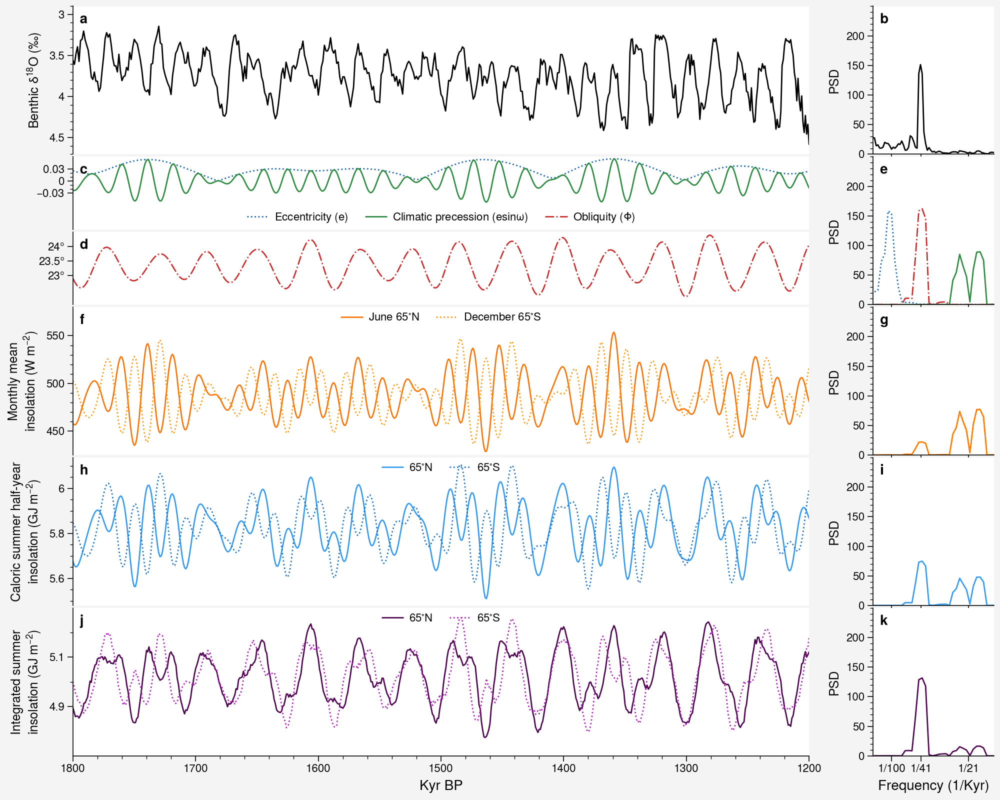

In [6]:
# Create figure
# =============

shape = [[1,1,1,1,1,1,1,1,1,1,1,1,0,2,2,],
         [1,1,1,1,1,1,1,1,1,1,1,1,0,2,2,],
         [3,3,3,3,3,3,3,3,3,3,3,3,0,5,5,],
         [4,4,4,4,4,4,4,4,4,4,4,4,0,5,5,],
         [6,6,6,6,6,6,6,6,6,6,6,6,0,7,7,],
         [6,6,6,6,6,6,6,6,6,6,6,6,0,7,7,],
         [8,8,8,8,8,8,8,8,8,8,8,8,0,9,9,],
         [8,8,8,8,8,8,8,8,8,8,8,8,0,9,9,],
         [10,10,10,10,10,10,10,10,10,10,10,10,0,11,11],
         [10,10,10,10,10,10,10,10,10,10,10,10,0,11,11],]

fig, axs = pplt.subplots(shape, sharey = False, sharex=False, figsize = (10, 8), space=0.2, abc=True, abcbbox=False, abcloc='ul', abcsize=10)

# Plot benthic d18O stack from Ahn et al., 2017
# =============================================

stack_line = axs[0].plot(prob_stack.time, prob_stack.value, color = 'black', ls = '-', lw = 1) 
axs[1].plot(prob_stack_psd.frequency, prob_stack_psd.amplitude, color = 'black', ls = '-', lw = 1) 
axs[0].invert_yaxis()
axs[0].format(ylim=(4.7, 2.9))

# Plot orbital parameters
# =======================

# eccentricity
ecc_line = axs[2].plot(preMPT.time, preMPT.ecc.values, color = 'blue9', ls = ':', lw = 1)
axs[4].plot(preMPT.ecc.spectrum().frequency, preMPT.ecc.spectrum().amplitude, color = 'blue9', ls = ':', lw = 1)

# climatic precession
pre_line = axs[2].plot(preMPT.time, preMPT.esinw.values, color = 'green9', lw = 1)
axs[2].format(ylim=(-0.12, 0.06), ylocator=[-0.03, 0., 0.03], yminorlocator=np.arange(-0.03, 0.03, 0.01))
axs[4].plot(preMPT.esinw.spectrum().frequency, preMPT.esinw.spectrum().amplitude, color = 'green9', lw = 1)

# obliquity
obl_line = axs[3].plot(preMPT.time, np.rad2deg(preMPT.obl.values), color = 'red9', ls = '-.', lw = 1)
axs[3].format(ylim=(22, 24.5), ylocator=[23, 23.5, 24], yminorlocator=[], yformatter='deg')
axs[4].plot(preMPT.obl.spectrum().frequency, preMPT.obl.spectrum().amplitude, color = 'red9', ls = '-.', lw = 1)

# legend
legend = axs[2].legend(handles=[ecc_line, pre_line, obl_line], labels = [r'Eccentricity ($e$)', 'Climatic precession ($e$sin$\omega$)', r'Obliquity ($\Phi$)'], loc = 'lc', prop={'size': 8}, frameon=False)

# Plot summer insolation metrics
# ==============================

# summer solstice insolation
I65N_JUN_line = axs[5].plot(preMPT.time, preMPT.JuneI_65N.values, color = 'orange', ls = '-', lw = 1) 
I65S_DEC_line = axs[5].plot(preMPT.time, preMPT.DecI_65S.values, color = 'tangerine', ls = ':', lw = 1) 
axs[5].format(ylim=(425, 580), ylocator=[450, 500, 550], yminorlocator=np.arange(450, 550+10,10))
axs[5].legend(handles=[I65N_JUN_line, I65S_DEC_line], labels = [r'June 65$^{\circ}N$', r'December 65$^{\circ}S$'], loc = 'uc', prop={'size': 8}, frameon=False)
axs[6].plot(preMPT.JuneI_65N.spectrum().frequency, preMPT.JuneI_65N.spectrum().amplitude, color = 'orange', ls = '-', lw = 1) 
axs[6].plot(preMPT.DecI_65S.spectrum().frequency, preMPT.DecI_65S.spectrum().amplitude, color = 'tangerine', ls = ':', lw = 1)  

# average caloric summer half-year insolation
I65N_CSH_line = axs[7].plot(preMPT.time, preMPT.CSH_65N.values, color = 'blue5', ls = '-', lw = 1) 
I65S_CSH_line = axs[7].plot(preMPT.time, preMPT.CSH_65S.values, color = 'blue8', ls = ':', lw = 1)
axs[7].legend(handles=[I65N_CSH_line, I65S_CSH_line], labels = [r'65$^{\circ}N$', r'65$^{\circ}S$'], loc = 'uc', prop={'size': 8}, frameon=False)
axs[8].plot(preMPT.CSH_65N.spectrum().frequency, preMPT.CSH_65N.spectrum().amplitude, color = 'blue5', ls = '-', lw = 1) 

# integrated summer insolation
I65N_ISI_line = axs[9].plot(preMPT.time, preMPT.ISI_65N.values, color = 'plum purple', ls = '-', lw = 1) 
I65S_ISI_line = axs[9].plot(preMPT.time, preMPT.ISI_65S.values, color = 'barney', ls = ':', lw = 1)
axs[9].legend(handles=[I65N_ISI_line, I65S_ISI_line], labels = [r'65$^{\circ}N$', r'65$^{\circ}S$'], loc = 'uc', prop={'size': 8}, frameon=False)
axs[9].format(ylim=(4.7, 5.3), ylocator = np.arange(4.9, 5.3, 0.2), yminorlocator = np.arange(4.9, 5.3, 0.1))
axs[10].plot(preMPT.ISI_65N.spectrum().frequency, preMPT.ISI_65N.spectrum().amplitude, color = 'plum purple', ls = '-', lw = 1) 


# Formatting
# ==========

for i in [0,2,3,5,7]:
    axs[i].spines[['bottom']].set_visible(False)
    axs[i].get_xaxis().set_visible(False)

for i in [0,2,3,5,7,9]:
    axs[i].spines[['top']].set_visible(False)

for i in np.arange(0,11):
    axs[i].spines[['right']].set_visible(False)

for i in [1,4,6,8,10]:
    axs[i].format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xticklabels=[r'1/100','1/41','1/21'], xlim = (0.001, 0.06), xticklabelsize=10, ylabel='PSD')
    axs[i].format(ylim = (0, 250), ylocator = [0, 50, 100, 150, 200])
    axs[i].spines[['top']].set_visible(False)
    if i != 10:
        axs[i].xaxis.set_ticklabels([])
    
# titles
axs.format(titlesize=7)
axs[0].format(ylabel='Benthic $\delta^{18}$O (‰)')
axs[5].format(ylabel='Monthly mean\ninsolation (W m$^{-2}$)')
axs[7].format(ylabel='Caloric summer half-year\ninsolation (GJ m$^{-2}$)')
axs[9].format(ylabel='Integrated summer\ninsolation (GJ m$^{-2}$)')

axs[9].format(xlabel = 'Kyr BP')
axs[10].format(xlabel = 'Frequency (1/Kyr)')

axs.format(ylabelsize=9, xlabelsize=10, ticklabelsize=8, grid=False)

axs[2].spines['bottom'].set_visible(False)
axs[2].get_xaxis().set_visible(False)

fig.save('f01.png', dpi=300)
fig.save('f01.pdf', dpi=300)

# Standard Experiment

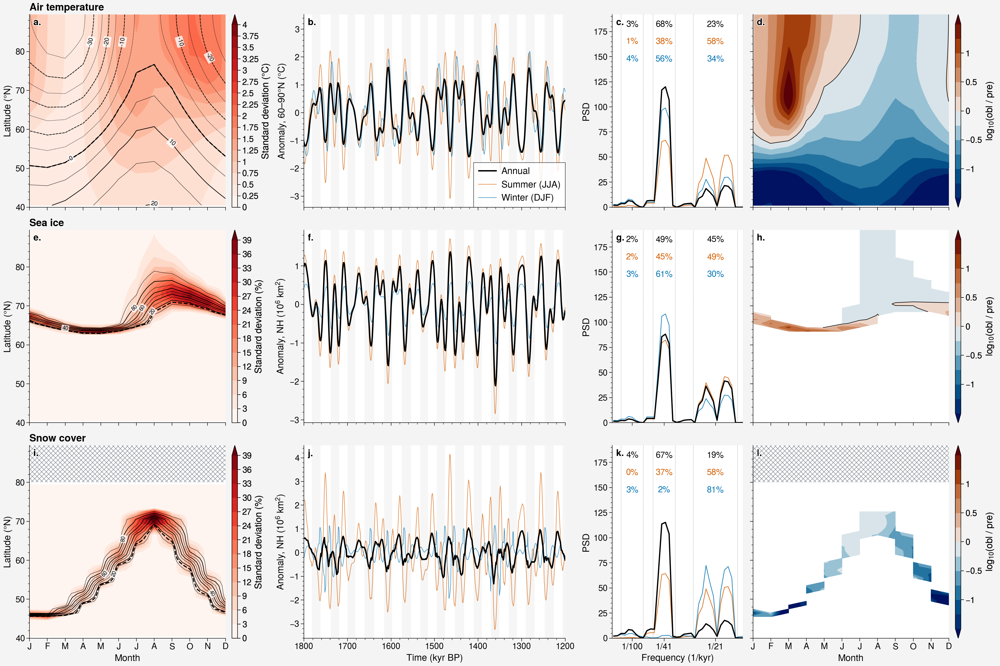

In [7]:
import matplotlib.pyplot as plt

FS_LABEL = 12      # axis and colorbar labels
FS_TICK  = 11      # tick labels
FS_TEXT  = 11      # spectral percentages
FS_LEG   = 12      # legend
ROW_H    = 4.0     # height per row (was 3.1)

# Calculate spectral power in each band
def calc_spec_power(f,a):
    
    oblfq = np.where( (f>obl_band[0]) & (f<obl_band[1]) )
    prefq = np.where( (f>pre_band[0]) & (f<pre_band[1]) )
    eccfq = np.where( (f>ecc_band[0]) & (f<ecc_band[1]) )

    o = np.round((np.nansum(a[oblfq])/np.nansum(a))*100,0)
    p = np.round((np.nansum(a[prefq])/np.nansum(a))*100,0)
    e = np.round((np.nansum(a[eccfq])/np.nansum(a))*100,0)

    return o,p,e

# Calculate spectral power for monthy fields (consistent with prio)
def spec(x, NW=2):
    s = pyleo.Series(time=t, value=x, time_name='Kyr BP', sort_ts='descending', verbose=False)
    p = s.standardize().interp().spectral(method='mtm', settings={'NW': NW})
    return np.asarray(p.frequency), np.asarray(p.amplitude)

# define hatch for no-land zone in contour
plt.rcParams['hatch.color'] = 'gray6'
plt.rcParams['hatch.linewidth'] = 0.6

# colormaps
CMAP_SD    = 'Reds'      # for standard deviation
CMAP_RATIO = 'vik'       # for ratio of obliquity to precession

# y-limit for PSD (as multiple of largest)
PSD_HEADROOM = 1.6 

# levels for obliquity/precession ratio
ratio_levels = np.arange(-1.5, 1.6, 0.25)

# experiment definitions
e   = preMPT               # experiment
lat = e.Var['lat']         # latitude
t   = np.asarray(e.time)   # time
mon = np.arange(12)        # months
ilat = np.where((lat > 40) & (lat < 90))[0] # latitude range (index)
la   = lat[ilat]                            # latitude range
high_obl = e.obl.values > e.obl.values.mean() # high obliquity values 

# fields
fds = [  # field, monthly field, when, skey, how, row name, units, where, scale, mean levels, labelled, highlight, SD levels, SD unit, label size
    ('Ta',      'Ta',          'annual', 'sarea', 'average', 'Air temperature', '°C',
     (60.0, 90.0), 1,   np.arange(-40, 21, 5),  np.arange(-40, 21, 10), 0.0, np.arange(0, 4.25, 0.25), '°C', 8),
    ('si_area', 'si_fraction', 'annual', 'oarea', 'sum',     'Sea ice',         '10$^6$ km$^2$',
     (0, 90),      100, np.arange(10, 100, 10), np.arange(20, 100, 20), 15,  np.arange(0, 42, 3),      '%', 7),
    ('sc_area', 'sc_fraction', 'annual', 'larea', 'sum',     'Snow cover',      '10$^6$ km$^2$',
     (0, 90),      100, np.arange(10, 100, 10), np.arange(20, 100, 20), 15,  np.arange(0, 42, 3),      '%', 7),
]
nfds = len(fds) 

# seasons
seasons = [('Annual',       'annual',   'k',       1.8, 1.0,  None),
           ('Summer (JJA)', 'JJA',     '#D55E00',  0.7, 0.75, None),
           ('Winter (DJF)', 'DJF',     '#0072B2',  0.7, 0.75, None)]

# Figure: time series ×4 | spectrum ×2 | mean & SD ×3 | ratio ×3
shape = [[r*4+1]*3 + [r*4+2]*4 + [r*4+3]*2 + [r*4+4]*3 for r in range(nfds)]
fig, axs = pplt.subplots(shape, figsize=(18, ROW_H * nfds), share=False)

# for setting constant spectral y-axis range
sp_axes, psd_max = [], 0.0 

for r, (var, mvar, whn, skey, meth, row_name, units, (lmn, lmx), scale,
        lev_mean, lev_lab, lev_hi, lev_sd, sd_unit, clab) in enumerate(fds):
    
    ax_ms, ax_ts, ax_sp, ax_r = axs[r*4:(r+1)*4]       # axes
    sp_axes.append(ax_sp)

    # (1) time series, (2) spectral
    for k, (slab, sn, c, lw, alpha, mk) in enumerate(seasons):

        # (1) time series
        x  = getattr(e, var).band(lmn, lmx, when = sn, method=meth)
        xa = x-x.mean()
        if k == 0:
            zorder=3
        else:
            zorder=2

        ax_ts.plot(t, xa, color=c, lw=lw, alpha=alpha, label=slab, zorder=zorder)

        # (2) spectral
        spc = getattr(e, var).spectrum(lmn, lmx, when = sn, reduce=meth)
        f = spc.frequency
        a = spc.amplitude
        psd_max = max(psd_max, np.nanmax(a[(f > 0.001) & (f < 0.06)]))
        if k==0:
            lw,alpha,zorder=1.6,1,3
        else:
            lw,alpha,zorder=0.9,0.85,2
        ax_sp.plot(f, a, color=c, lw=lw, alpha=alpha, zorder=zorder)
        # add text
        ytxt = 0.97 - 0.09 * k
        # add spectral power in each band to text
        ob,pr,ee=calc_spec_power(f,a)
        for b, xpos in ((ob, 1/41), (pr, 1/21), (ee, 1/100)):
            ax_sp.text(xpos, ytxt, f'{b:.0f}%', transform=ax_sp.get_xaxis_transform(),
                       ha='center', va='top', fontsize=FS_TEXT, color=c)

    lo, hi = ax_ts.get_ylim()
    ax_ts.fill_between(t, lo, hi, where=high_obl, color='gray', alpha=0.08, lw=0) # add gray shading for obl
    ax_ts.set_ylim(lo, hi)
    region = 'NH' if (lmn, lmx) == (0, 90) else f'{lmn:.0f}–{lmx:.0f}°N'
    ax_ts.format(ylabel=f'Anomaly, {region} ({units})', xreverse=True)
    if r == 0:
        ax_ts.legend(loc='lr', ncols=1, prop={'size': FS_LEG}, frameon=True)

    for b in (obl_band, pre_band, ecc_band):
        for edge in b:
            ax_sp.axvline(edge, color='gray6', lw=0.6, ls=':', zorder=0)
    ax_sp.format(xlocator=[1/100, 1/41, 1/21], xminorlocator=[], xlim=(0.001, 0.06), ylabel='PSD')

    # (3) standard deviation (colour) with mean state (contours)
    M = getattr(e, mvar).monthly[:, ilat, :] * scale
    mean, sd = np.nanmean(M, axis=0), np.nanstd(M, axis=0) # calc. mean and standard deviation
    cf_sd = ax_ms.contourf(mon, la, sd, levels=lev_sd, cmap=CMAP_SD, extend='max')
    ax_ms.contour(mon, la, mean, levels=lev_mean, colors='k', linewidths=0.4)
    cs = ax_ms.contour(mon, la, mean, levels=lev_lab, colors='k', linewidths=0.8)
    labels = ax_ms.clabel(cs, fmt='%g', fontsize=clab, inline=True, inline_spacing=2)
    for txt in labels:
        txt.set_bbox(dict(facecolor='white', edgecolor='none', alpha=0.8, pad=0.6,
                          boxstyle='round,pad=0.15'))
    ax_ms.contour(mon, la, mean, levels=[lev_hi], colors='k', linewidths=1.4, linestyles='--')
    # apply hatch to no-land region
    missing = (e.Var[skey][ilat] <= 0).astype(float)
    if missing.any():
        ax_ms.contourf(mon, la, np.repeat(missing[:, None], 12, axis=1), levels=[0.5, 1.5], colors='none', hatches=['xxxx'], zorder=1)
    ax_ms.colorbar(cf_sd, loc='r', width=0.1, label=f'Standard deviation ({sd_unit})',
                   labelsize=FS_LABEL, ticklabelsize=FS_TICK)
    ax_ms.format(title=row_name, titleloc='left', titleweight='bold', titlesize=FS_LABEL + 1,
                 ylim=(40, 89.5), ylabel='Latitude (°N)', xlocator=mon, xminorlocator=[])

    # (4) obliquity / precession ratio
    M = getattr(e, mvar).monthly
    min_std = 0.01 * np.nanmax(np.nanstd(M[:, ilat, :], axis=0))
    R = np.full((ilat.size, 12), np.nan)
    for a_, j in enumerate(ilat):
        if e.Var[skey][j] <= 0: # skip where surface type not present
            continue
        for m in range(12):
            x = np.asarray(M[:, j, m], float) # for every kyr of that lat/month
            if not np.all(np.isfinite(x)) or np.std(x) < min_std:
                R[a_, m] = np.nan
                continue
            f, a = spec(x - x.mean())
            po = np.nansum(a[(f > obl_band[0]) & (f < obl_band[1])])
            pp = np.nansum(a[(f > pre_band[0]) & (f < pre_band[1])])
            if pp > 0:
                R[a_, m] = po / pp
            else:
                R[a_, m] = np.nan
    with np.errstate(divide='ignore', invalid='ignore'):
        L = np.log10(R)
    cf_r = ax_r.contourf(mon, la, L, levels=ratio_levels, cmap=CMAP_RATIO, extend='both')
    ax_r.contour(mon, la, L, levels=[0], colors='k', linewidths=0.7)
    # apply hatch to no-land region
    missing = (e.Var[skey][ilat] <= 0).astype(float)
    if missing.any():
        ax_r.contourf(mon, la, np.repeat(missing[:, None], 12, axis=1), levels=[0.5, 1.5], colors='none', hatches=['xxxx'], zorder=1)
    ax_r.colorbar(cf_r, loc='r', width=0.1, label='log$_{10}$(obl / pre)', ticks=[-1, -0.5, 0, 0.5, 1],
                  labelsize=FS_LABEL, ticklabelsize=FS_TICK)
    ax_r.format(ylim=(40, 89.5), xlocator=mon, xminorlocator=[], yticklabels=[])

    if r == nfds - 1:
        ax_ts.format(xlabel='Time (kyr BP)',xticklabels=None)
        ax_sp.format(xlabel='Frequency (1/kyr)',xticklabels=['1/100', '1/41', '1/21'])
        for ax in (ax_ms, ax_r):
            ax.format(xlabel='Month',xticklabels=list('JFMAMJJASOND'))     
    else:
        ax_ts.format(xlabel='',xticklabels=[])
        ax_sp.format(xlabel='',xticklabels=[])
        for ax in (ax_ms, ax_r):
            ax.format(xlabel='',xticklabels=[])
            

# common PSD y-limit with headroom for the percentage labels
for ax in sp_axes:
    ax.format(ylim=(0, PSD_HEADROOM * psd_max))

axs.format(abc='a.', abcloc='ul', abcsize=FS_LABEL, labelsize=FS_LABEL, ticklabelsize=FS_TICK)
for ax in axs:
    ax.spines[['top', 'right']].set_visible(False)
    ax.format(grid=False)

fig.save('f03.png', dpi=300)
fig.save('f03.pdf', dpi=300)

# Boundary experiments

                        $T_{PI}$             $T_A$         $T_{LGM}$
Ta                        74/18             68/23             49/38    (obl%/pre%)
si_area                   56/39             49/45             38/49    (obl%/pre%)
smbp_rate                 45/50             39/57             18/76    (obl%/pre%)


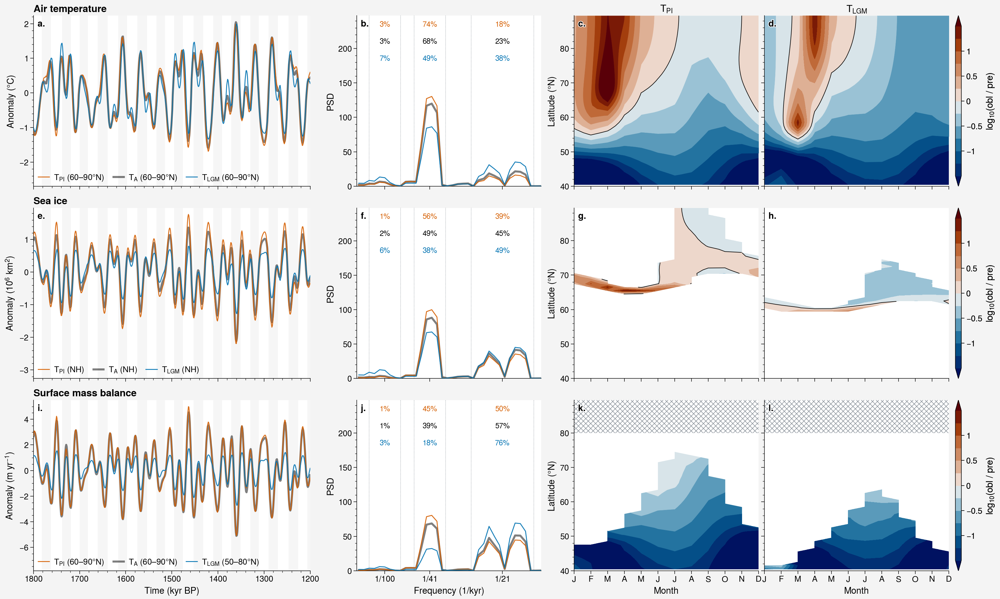

In [8]:
import numpy as np
import proplot as pplt
import pyleoclim as pyleo
import matplotlib.pyplot as plt

FS_LABEL, FS_TICK, FS_TEXT, FS_LEG = 11, 10, 9, 10
ROW_H, PSD_HEADROOM = 3.4, 1.9
LEG_ROOM = 0.2                                         # extra bottom space in time-series panels for the legend
ratio_levels = np.arange(-1.5, 1.6, 0.25)
mon = np.arange(12)
plt.rcParams['hatch.color'] = 'gray6'
plt.rcParams['hatch.linewidth'] = 0.6

# boundary-condition experiments: (label, cache key, object, colour, lw, alpha, zorder)
BC = [(r'$T_{PI}$',  'T_PI',  pi,     '#D55E00', 1.1, 0.9,  3),   # adjust object names to your runs
      (r'$T_A$',     'T_A',   preMPT, 'k',       2.5, 0.5, 2),
      (r'$T_{LGM}$', 'T_LGM', LGM,    '#0072B2', 1.1, 0.9,  3)]
MAPS = [BC[0], BC[2]]                                                    # ratio maps for PI, preMPT and LGM

# fields: (series var, monthly var, when, area key, method, row name, units, lat range, scale)
# lat range is either a (min, max) tuple for all runs, or a dict keyed by BC cache key with a 'default'
fds = [('Ta',        'Ta',          'annual', 'sarea', 'average', 'Air temperature',      '°C',             (60, 90), 1),
       ('si_area',   'si_fraction', 'annual', 'oarea', 'sum',     'Sea ice',              '10$^6$ km$^2$', (0, 90),  100),
       ('smbp_rate', 'smbp_rate',   'annual', 'larea', 'average', 'Surface mass balance', 'm yr$^{-1}$',
        {'default': (60, 90), 'T_LGM': (50, 80)}, 1)]
nfds = len(fds)


def lat_range_for(rng, key):
    return rng.get(key, rng['default']) if isinstance(rng, dict) else rng


def region_label(lmn, lmx):
    return 'NH' if (lmn, lmx) == (0, 90) else f'{lmn:.0f}–{lmx:.0f}°N'


def spec_series(t, x, NW=2):
    s = pyleo.Series(time=t, value=x, time_name='Kyr BP', sort_ts='descending', verbose=False)
    p = s.standardize().interp().spectral(method='mtm', settings={'NW': NW})
    return np.asarray(p.frequency), np.asarray(p.amplitude)


def ratio_map(e, name, mvar, skey, lat_range=(40, 90)):
    """log10(obl/pre band power) per latitude and month, cached to disk."""
    cache = f'ratio_map_{mvar}_{name}.npz'
    try:
        d = np.load(cache)
        return d['lat'], d['L']
    except FileNotFoundError:
        pass
    lat  = np.asarray(e.Var['lat']); t = np.asarray(e.time)
    ilat = np.where((lat > lat_range[0]) & (lat < lat_range[1]))[0]
    M    = np.asarray(getattr(e, mvar).monthly, float)
    min_std = 0.01 * np.nanmax(np.nanstd(M[:, ilat, :], axis=0))
    R = np.full((ilat.size, 12), np.nan)
    for a_, j in enumerate(ilat):
        if e.Var[skey][j] <= 0:
            continue
        for m in range(12):
            x = M[:, j, m]
            if not np.all(np.isfinite(x)) or np.std(x) < min_std:
                continue
            f, a = spec_series(t, x - x.mean())
            po = np.nansum(a[(f > obl_band[0]) & (f < obl_band[1])])
            pp = np.nansum(a[(f > pre_band[0]) & (f < pre_band[1])])
            R[a_, m] = po / pp if pp > 0 else np.nan
    with np.errstate(divide='ignore', invalid='ignore'):
        L = np.log10(R)
    np.savez(cache, lat=lat[ilat], L=L)
    return lat[ilat], L


# ---------------------------------------------------------------------------
# figure: time series ×3 | spectrum ×2 | ratio PI ×2 | ratio preMPT ×2 | ratio LGM ×2
# ---------------------------------------------------------------------------

NP = 2 + len(MAPS)                                      # time series + spectrum + one per map
shape = [[r*NP + 1]*3 + [r*NP + 2]*2 + sum(([r*NP + 3 + i]*2 for i in range(len(MAPS))), [])
         for r in range(nfds)]
# 0 = gap inside a spanning panel; None = tight layout; 0.8 between maps (no y labels)
wspace = [0, 0, None, 0, None] + [0, 0.8] * (len(MAPS) - 1) + [0]
fig, axs = pplt.subplots(shape, figsize=(17, ROW_H * nfds), share=False, wspace=wspace)
sp_axes, psd_max = [], 0.0

print(f'{"":14s}' + ''.join(f'{lab:>18s}' for lab, *_ in BC))
for r, (var, mvar, whn, skey, meth, row_name, units, lat_rng, scale) in enumerate(fds):
    ax_ts, ax_sp, *ax_maps = axs[r*NP:(r + 1)*NP]
    sp_axes.append(ax_sp)
    last, txt = r == nfds - 1, []

    # (1) time series and (2) spectra, standard run in grey as reference
    for k, (lab, key, e, c, lw, al, z) in enumerate(BC):
        lmn, lmx = lat_range_for(lat_rng, key)
        region = region_label(lmn, lmx)
        t  = np.asarray(e.time)
        x  = np.asarray(getattr(e, var).band(lmn, lmx, when=whn, method=meth), float)
        ax_ts.plot(t, x - x.mean(), color=c, lw=lw, alpha=al, zorder=z, label=f'{lab} ({region})')

        spc = getattr(e, var).spectrum(lmn, lmx, when=whn, reduce=meth)
        f, a = np.asarray(spc.frequency), np.asarray(spc.amplitude)
        psd_max = max(psd_max, np.nanmax(a[(f > 0.001) & (f < 0.06)]))
        ax_sp.plot(f, a, color=c, lw=lw, alpha=al, zorder=z)
        ob, pr, ec = calc_spec_power(f, a)
        for b, xpos in ((ob, 1/41), (pr, 1/21), (ec, 1/100)):
            ax_sp.text(xpos, 0.97 - 0.1 * k, f'{b:.0f}%', transform=ax_sp.get_xaxis_transform(),
                       ha='center', va='top', fontsize=FS_TEXT, color=c)
        txt.append(f'{ob:5.0f}/{pr:<3.0f}')
    print(f'{var:14s}' + ''.join(f'{s:>18s}' for s in txt) + '   (obl%/pre%)')

    # make room at the bottom for the legend, then shade high-obliquity intervals
    lo, hi = ax_ts.get_ylim()
    lo -= LEG_ROOM * (hi - lo)
    high_obl = preMPT.obl.values > preMPT.obl.values.mean()
    ax_ts.fill_between(np.asarray(preMPT.time), lo, hi, where=high_obl, color='gray', alpha=0.08, lw=0)
    ax_ts.format(ylim=(lo, hi), xreverse=True, ylabel=f'Anomaly ({units})',
                 title=row_name, titleloc='left', titleweight='bold', titlesize=FS_LABEL + 1,
                 xlabel='Time (kyr BP)' if last else '', xticklabels=None if last else [])
    ax_ts.legend(loc='ll', ncols=3, frameon=False, prop={'size': FS_LEG},
                 handlelength=1.5, columnspacing=1.0)

    for b in (obl_band, pre_band, ecc_band):
        for edge in b:
            ax_sp.axvline(edge, color='gray6', lw=0.6, ls=':', zorder=0)
    ax_sp.format(xlocator=[1/100, 1/41, 1/21], xminorlocator=[], xlim=(0.001, 0.06), ylabel='PSD',
                 xlabel='Frequency (1/kyr)' if last else '',
                 xticklabels=['1/100', '1/41', '1/21'] if last else [])

    # (3–5) obl/pre ratio maps for PI, preMPT and LGM, with the mean 15% sea ice edge
    for i, (ax, (lab, key, e, *_)) in enumerate(zip(ax_maps, MAPS)):
        first = i == 0
        la, L = ratio_map(e, key, mvar, skey)
        cf = ax.contourf(mon, la, L, levels=ratio_levels, cmap='vik', extend='both')
        ax.contour(mon, la, L, levels=[0], colors='k', linewidths=0.7)
        lat_e = np.asarray(e.Var['lat']); il = np.where((lat_e > 40) & (lat_e < 90))[0]
        missing = (np.asarray(e.Var[skey])[il] <= 0).astype(float)
        if missing.any():
            ax.contourf(mon, lat_e[il], np.repeat(missing[:, None], 12, axis=1), levels=[0.5, 1.5],
                        colors='none', hatches=['xxxx'], zorder=1)
        ax.format(ylim=(40, 89.5), xlocator=mon, xminorlocator=[],
                  xticklabels=list('JFMAMJJASOND') if last else [], xlabel='Month' if last else '',
                  ylabel='Latitude (°N)' if first else '', yticklabels=None if first else [])
        if r == 0:
            ax.format(title=lab, titlesize=FS_LABEL + 1)
    ax_maps[-1].colorbar(cf, loc='r', width=0.1, label='log$_{10}$(obl / pre)', ticks=[-1, -0.5, 0, 0.5, 1],
                         labelsize=FS_LABEL, ticklabelsize=FS_TICK)

for ax in sp_axes:
    ax.format(ylim=(0, PSD_HEADROOM * psd_max))
axs.format(abc='a.', abcloc='ul', abcsize=FS_LABEL, labelsize=FS_LABEL, ticklabelsize=FS_TICK)
for ax in axs:
    ax.spines[['top', 'right']].set_visible(False)
    ax.format(grid=False)
fig.save('f08.png', dpi=300)
fig.save('f08.pdf', dpi=300)

# Obliquity and Precession Experiments

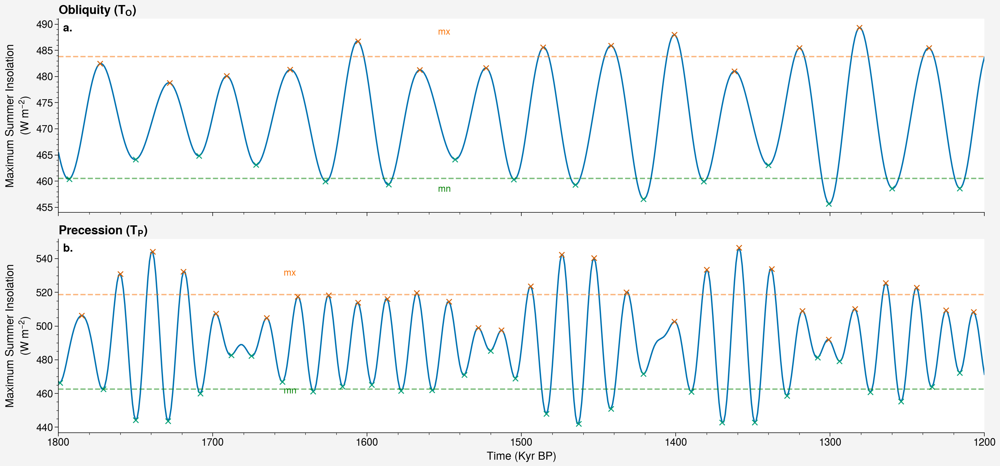

In [9]:
i65N = np.where((preMPT.Var['lat'] >= 64.5) & (preMPT.Var['lat'] <= 65.5))[0]
for exp in [preMPT, preMPTo, preMPTp]:
    max_65N = exp.I.monthly[:, i65N, :].mean(axis=1).max(axis=1)
    exp.add_series('max_65N', max_65N, units='Maximum monthly average insolation (W m2)')

# Find maximim and minima
# =======================

from scipy.signal import find_peaks

# anomalies
obl_anomaly = preMPTo.max_65N.values-preMPTo.max_65N.values.mean()
pre_anomaly = preMPTp.max_65N.values-preMPTp.max_65N.values.mean()
std_anomaly = preMPT.max_65N.values-preMPT.max_65N.values.mean()

# maximima
obl_peaks, _ = find_peaks(obl_anomaly, height=0)
pre_peaks, _ = find_peaks(pre_anomaly, height=0)
std_peaks, _ = find_peaks(std_anomaly, height=0)
obl_peaks    = obl_peaks.astype(int)
pre_peaks    = pre_peaks.astype(int)
std_peaks    = std_peaks.astype(int)

# minima
obl_troughs, _ = find_peaks(-obl_anomaly, height=0)
pre_troughs, _ = find_peaks(-pre_anomaly, height=0)
std_troughs, _ = find_peaks(-std_anomaly, height=0)
obl_troughs    = obl_troughs.astype(int)
pre_troughs    = pre_troughs.astype(int)
std_troughs    = std_troughs.astype

FS_LABEL = 12      # axis and colorbar labels
FS_TICK  = 11      # tick labels
FS_TEXT  = 11      # spectral percentages
FS_LEG   = 12      # legend
ROW_H    = 4.0     # height per row (was 3.1)

shape = [[1,1,1,1,1,1,1,1,1],
         [1,1,1,1,1,1,1,1,1],
         [1,1,1,1,1,1,1,1,1],
         [2,2,2,2,2,2,2,2,2],
         [2,2,2,2,2,2,2,2,2],
         [2,2,2,2,2,2,2,2,2],]


fig, axs = pplt.subplots(shape, figsize=(15,7), sharex=False, sharey=False)

# obliquity (fixed precession)
axs[0].plot(preMPTo.time, preMPTo.max_65N.values)
axs[0].plot(preMPTo.time[obl_peaks], preMPTo.max_65N.values[obl_peaks], "x")
axs[0].plot(preMPTo.time[obl_troughs], preMPTo.max_65N.values[obl_troughs], "x")
axs[0].axhline(preMPTo.max_65N.values[obl_peaks].mean(), color = 'orange', linestyle = 'dashed', alpha=0.5) 
axs[0].axhline(preMPTo.max_65N.values[obl_troughs].mean(), color = 'green', linestyle = 'dashed', alpha=0.5) 
axs[0].text(1550, 488, 'mx', color = 'orange', fontsize=10, horizontalalignment='center') 
axs[0].text(1550, 458, 'mn', color = 'green', fontsize=10, horizontalalignment='center') 

# precession (fixed obliquity)
axs[1].plot(preMPTp.time, preMPTp.max_65N.values)
axs[1].plot(preMPTp.time[pre_peaks], preMPTp.max_65N.values[pre_peaks], "x")
axs[1].plot(preMPTp.time[pre_troughs], preMPTp.max_65N.values[pre_troughs], "x")
axs[1].axhline(preMPTp.max_65N.values[pre_peaks].mean(), color = 'orange', linestyle = 'dashed', alpha=0.5) 
axs[1].axhline(preMPTp.max_65N.values[pre_troughs].mean(), color = 'green', linestyle = 'dashed', alpha=0.5) 
axs[1].text(1650, 530, 'mx', color = 'orange', fontsize=10, horizontalalignment='center') 
axs[1].text(1650, 460, 'mn', color = 'green',  fontsize=10, horizontalalignment='center') 

axs.format(ylabel='Maximum Summer Insolation\n(W m$^{-2}$)')
axs[0].format(title='Obliquity (T$_{O}$)', titleloc='left', titleweight='bold', titlesize=FS_LABEL + 1)
axs[1].format(title='Precession (T$_{P}$)', titleloc='left', titleweight='bold', titlesize=FS_LABEL + 1)

axs.format(abc='a.', abcloc='ul', abcsize=FS_LABEL, labelsize=FS_LABEL, ticklabelsize=FS_TICK)
for ax in axs:
    ax.spines[['top', 'right']].set_visible(False)
    ax.format(grid=False)

axs[1].format(xlabel='Time (Kyr BP)')
axs[0].format(xlabel='',xticklabels=[])

fig.save('fA1.png', dpi=300)
fig.save('fA1.pdf', dpi=300)

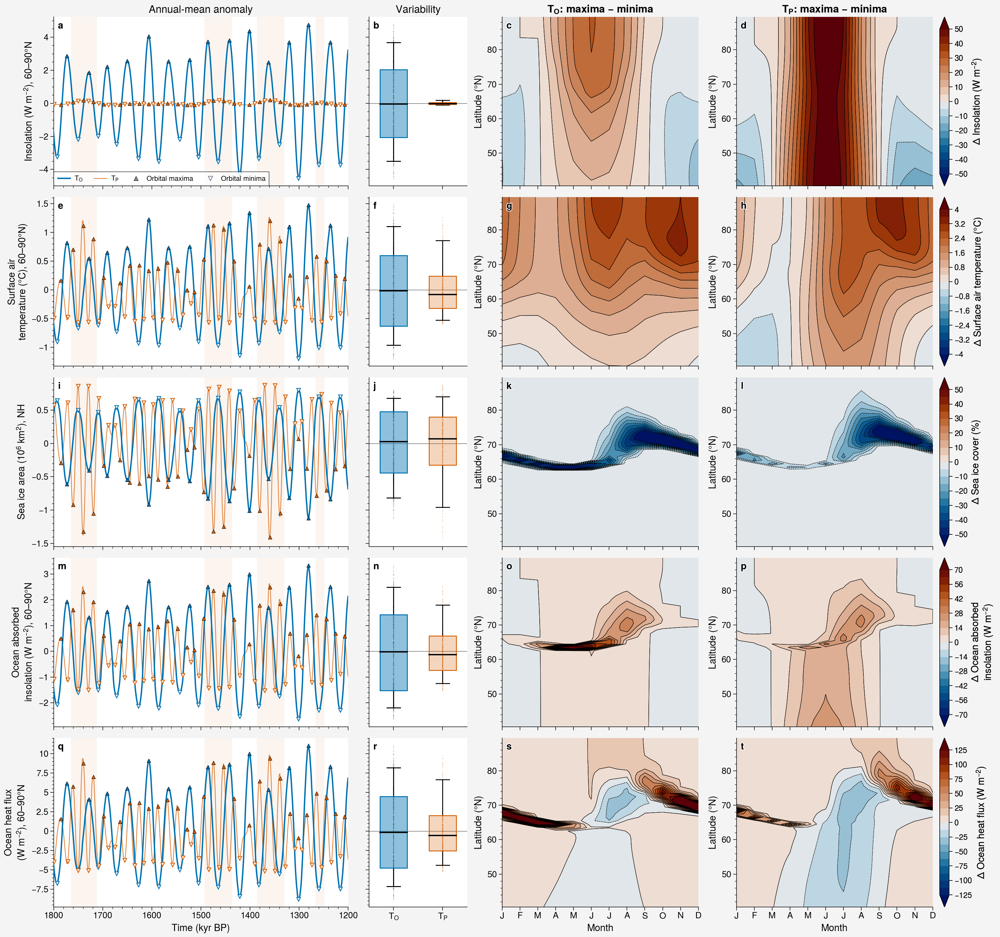

In [10]:
n_levels=21
mark_extremes=True

# fields to plot
fds = [
    ('I',             'I',             'Insolation (W m$^{-2}$)',         50,  (60,90), 'average', 'Insolation (W m$^{-2}$), 60–90°N',),
    ('Ta',            'Ta',            'Surface air temperature (°C)',             4,   (60,90), 'average',  'Surface air\ntemperature (°C), 60–90°N)',),
    ('si_area',       'si_fraction',   'Sea ice cover (%)',                    50,  (0,90),  'sum',     'Sea ice area (10$^6$ km$^2$), NH'),
    ('rsdsnet_ocean', 'rsdsnet_ocean', 'Ocean absorbed\ninsolation (W m$^{-2}$)',  70,  (60,90), 'average',  'Ocean absorbed\ninsolation (W m$^{-2}$), 60–90°N',),
    ('ohf',           'ohf',           'Ocean heat flux (W m$^{-2}$)',            125, (60,90), 'average',  'Ocean heat flux\n(W m$^{-2}$), 60–90°N'),
]
nfds = len(fds)

# obl/pre colours
OBL_C, PRE_C = '#0072B2', '#D55E00'
STYLE = {'T$_{O}$': dict(lw=1.6, alpha=1.0,  zorder=3),
         'T$_{P}$': dict(lw=0.9, alpha=0.75, zorder=2)}

# months
mlab, months = list('JFMAMJJASOND'), np.arange(1, 13)

# latitudes
lat_all = preMPT.Var['lat']
lati = np.where((lat_all >= 40) & (lat_all <= 90))[0]
lat  = lat_all[lati]
latticks=np.arange(40, 91, 10)

# experiments
runs = [('T$_{O}$', preMPTo, obl_peaks, obl_troughs, OBL_C),
        ('T$_{P}$', preMPTp, pre_peaks, pre_troughs, PRE_C)]

def high_ecc_spans(time, ecc, thresh):
    """(start, end) times of continuous stretches where ecc > thresh."""
    time = np.asarray(time); high = np.asarray(ecc) > thresh
    d = np.diff(high.astype(int))
    starts = list(np.where(d == 1)[0] + 1); ends = list(np.where(d == -1)[0] + 1)
    if high[0]:  starts = [0] + starts
    if high[-1]: ends = ends + [high.size]
    return [(time[s], time[e - 1]) for s, e in zip(starts, ends)]

ecc_ref   = preMPTp.ecc.values                                   # eccentricity varies in T_P
ecc_spans = high_ecc_spans(preMPTp.time, ecc_ref, 0.035)


# define figure
shape = [[4*i + 1]*3 + [4*i + 2]*1 + [4*i + 3]*2 + [4*i + 4]*2 for i in range(nfds)]
fig, axs = pplt.subplots(shape, figsize=(16, 3.0 * nfds), share=False)

# plot each field
# ---------------

for row, (v, cv, ctitle, rng, (lmn, lmx), mth, stitle) in enumerate(fds):

    # modify scale
    if cv in ('sc_fraction', 'si_fraction'):
        scale = 100.0
    else:
        scale = 1.0

    # contour levels
    levels = np.linspace(-rng, rng, n_levels)

    # axes
    ax_ts, ax_box, ax_o, ax_p = axs[4*row: 4*(row + 1)]

    # (1) time series of annual-mean anomalies
    series = []
    for lab, ex, pks, trs, c in runs: # for each experiment

        # annual mean anom
        s = getattr(ex,v).band(lmn, lmx, method=mth, when='annual')
        s = s - s.mean()
        series.append(s)
        t = np.asarray(ex.time)

        # add high eccentricity
        for t0, t1 in ecc_spans:
            ax_ts.axvspan(t0, t1, color=PRE_C, alpha=0.03, lw=0, zorder=0)

        # plot
        ax_ts.plot(t, s, color=c, label=lab, **STYLE[lab])
         
        if mark_extremes: # mark extremes in obliquity and precession

            # peaks
            ax_ts.plot(t[pks], s[pks], '^', ms=4.5, color=c, mec='k', mew=0.4, zorder=4) 

            # troughs
            ax_ts.plot(t[trs], s[trs], 'v', ms=4.5, mfc='white', mec=c, mew=0.9, zorder=4)  

        if (row == nfds - 1):
            ax_ts.format(ylabel=f'{stitle}', xreverse=True, xlabel='Time (kyr BP)', xticklabels=None)
        else:
             ax_ts.format(ylabel=f'{stitle}', xreverse=True, xlabel='', xticklabels=[])


        if row == 0:
            from matplotlib.lines import Line2D
            handles = [Line2D([0], [0], color=OBL_C, lw=1.6),
                       Line2D([0], [0], color=PRE_C, lw=0.9, alpha=0.75),
                       Line2D([0], [0], marker='^', ls='', ms=5, color='gray6', mec='k', mew=0.4),
                       Line2D([0], [0], marker='v', ls='', ms=5, mfc='white', mec='gray6', mew=0.9),]
            ax_ts.legend(handles, ['T$_{O}$', 'T$_{P}$', 'Orbital maxima', 'Orbital minima'],
                         loc='ll', ncols=4, prop={'size': 8}, frameon=True)


        # (2) box plot, sharing the time-series y-range
        draw_boxplot(ax_box, series, ['T$_{O}$', 'T$_{P}$'], [OBL_C, PRE_C])
        ax_box.set_ylim(ax_ts.get_ylim())
        ax_box.axhline(0, color='k', lw=0.5, alpha=0.4)
        if (row == nfds - 1):
            ax_box.format(xlocator=[1, 2], xticklabels=['T$_{O}$', 'T$_{P}$'], xminorlocator=[], yticklabels=[])
        else:
            ax_box.format(xlocator=[1, 2], xticklabels=[], xminorlocator=[], yticklabels=[])


        # (3, 4) composites: maxima − minima
        for col, (ax, (lab, ex, pks, trs, c)) in enumerate(((ax_o, runs[0]), (ax_p, runs[1]))):
            mon  = getattr(ex, cv).monthly
            anom = (mon[pks][:, lati, :].mean(axis=0) - mon[trs][:, lati, :].mean(axis=0)) * scale
            m = ax.contourf(months, lat, anom, cmap='vik', levels=levels, extend='both')
            ax.contour(months, lat, anom, levels=levels, colors='k', linewidths=0.4)

            if row == nfds-1:
                ax.format(xlim=(1, 12), xlocator=months, xminorlocator=[], ylim=(lat.min(), lat.max()), ylocator=latticks, ylabel='Latitude (°N)', yticklabels=None, xticklabels=mlab, xlabel='Month')
            else:
                ax.format(xlim=(1, 12), xlocator=months, xminorlocator=[], ylim=(lat.min(), lat.max()), ylocator=latticks, ylabel='Latitude (°N)', yticklabels=None, xticklabels=[], xlabel='')
   
    cb = ax_p.colorbar(m, loc='r', width=0.15, ticks=levels)
    cb.set_label(r'$\Delta$ ' + ctitle, size=11)
    cb.ax.tick_params(labelsize=9)

# column titles
axs[0].format(title='Annual-mean anomaly', titlesize=12)
axs[1].format(title='Variability', titlesize=12)
axs[2].format(title='T$_{O}$: maxima − minima', titleweight='bold', titlesize=12)
axs[3].format(title='T$_{P}$: maxima − minima', titleweight='bold', titlesize=12)

axs.format(labelsize=11, ticklabelsize=10, abc=True, abcloc='ul', abcsize=11)
for ax in axs:
    ax.spines[['top', 'right']].set_visible(False)
    ax.format(grid=False)
fig.save('f04.png', dpi=300)
fig.save('f04.pdf', dpi=300)

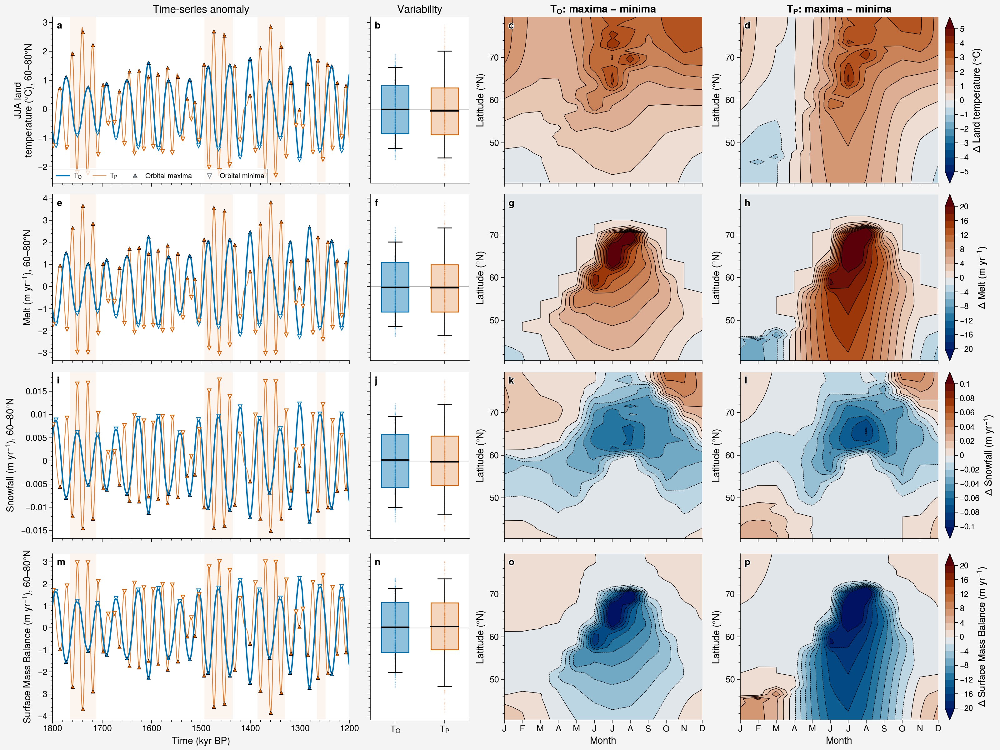

In [11]:
n_levels=21

# fields to plot
fds = [
    ('Tl', 'Tl', 'Land temperature (°C)', 5,  (60,80), 'average', 'JJA land\ntemperature (°C), 60–80°N','JJA'),
    ('pmelt', 'pmelt', 'Melt (m yr$^{-1}$)', 20,  (60,80), 'average', 'Melt (m yr$^{-1}$), 60–80°N','annual'),
    ('snowfall_land', 'snowfall_land', 'Snowfall (m yr$^{-1}$)', 0.1,  (60,80), 'average', 'Snowfall (m yr$^{-1}$), 60–80°N','annual'),
    ('smbp_rate', 'smbp_rate', 'Surface Mass Balance (m yr$^{-1}$)', 20,  (60,80), 'average', 'Surface Mass Balance (m yr$^{-1}$), 60–80°N','annual')
]

nfds = len(fds)

# obl/pre colours
OBL_C, PRE_C = '#0072B2', '#D55E00'
STYLE = {'T$_{O}$': dict(lw=1.6, alpha=1.0,  zorder=3),
         'T$_{P}$': dict(lw=0.9, alpha=0.75, zorder=2)}

# months
mlab, months = list('JFMAMJJASOND'), np.arange(1, 13)

# latitudes
lat_all = preMPT.Var['lat']
lati = np.where((lat_all >= 40) & (lat_all <= 80))[0]
lat  = lat_all[lati]
latticks=np.arange(40, 81, 10)

# experiments
runs = [('T$_{O}$', preMPTo, obl_peaks, obl_troughs, OBL_C),
        ('T$_{P}$', preMPTp, pre_peaks, pre_troughs, PRE_C)]

def high_ecc_spans(time, ecc, thresh):
    """(start, end) times of continuous stretches where ecc > thresh."""
    time = np.asarray(time); high = np.asarray(ecc) > thresh
    d = np.diff(high.astype(int))
    starts = list(np.where(d == 1)[0] + 1); ends = list(np.where(d == -1)[0] + 1)
    if high[0]:  starts = [0] + starts
    if high[-1]: ends = ends + [high.size]
    return [(time[s], time[e - 1]) for s, e in zip(starts, ends)]

ecc_ref   = preMPTp.ecc.values                                   # eccentricity varies in T_P
ecc_spans = high_ecc_spans(preMPTp.time, ecc_ref, 0.035)


# define figure
shape = [[4*i + 1]*3 + [4*i + 2]*1 + [4*i + 3]*2 + [4*i + 4]*2 for i in range(nfds)]
fig, axs = pplt.subplots(shape, figsize=(16, 3.0 * nfds), share=False)

# plot each field
# ---------------

for row, (v, cv, ctitle, rng, (lmn, lmx), mth, stitle, whn) in enumerate(fds):

    # modify scale
    if cv in ('sc_fraction', 'si_fraction'):
        scale = 100.0
    else:
        scale = 1.0

    # contour levels
    levels = np.linspace(-rng, rng, n_levels)

    # axes
    ax_ts, ax_box, ax_o, ax_p = axs[4*row: 4*(row + 1)]

    # (1) time series of annual-mean anomalies
    series = []
    for lab, ex, pks, trs, c in runs: # for each experiment

        # annual mean anom
        s = getattr(ex,v).band(lmn, lmx, method=mth, when=whn)
        s = s - s.mean()
        series.append(s)
        t = np.asarray(ex.time)

        # add high eccentricity
        for t0, t1 in ecc_spans:
            ax_ts.axvspan(t0, t1, color=PRE_C, alpha=0.03, lw=0, zorder=0)

        # plot
        ax_ts.plot(t, s, color=c, label=lab, **STYLE[lab])
         
        if mark_extremes: # mark extremes in obliquity and precession

            # peaks
            ax_ts.plot(t[pks], s[pks], '^', ms=4.5, color=c, mec='k', mew=0.4, zorder=4) 

            # troughs
            ax_ts.plot(t[trs], s[trs], 'v', ms=4.5, mfc='white', mec=c, mew=0.9, zorder=4)  

        if (row == nfds - 1):
            ax_ts.format(ylabel=f'{stitle}', xreverse=True, xlabel='Time (kyr BP)', xticklabels=None)
        else:
             ax_ts.format(ylabel=f'{stitle}', xreverse=True, xlabel='', xticklabels=[])


        if row == 0:
            from matplotlib.lines import Line2D
            handles = [Line2D([0], [0], color=OBL_C, lw=1.6),
                       Line2D([0], [0], color=PRE_C, lw=0.9, alpha=0.75),
                       Line2D([0], [0], marker='^', ls='', ms=5, color='gray6', mec='k', mew=0.4),
                       Line2D([0], [0], marker='v', ls='', ms=5, mfc='white', mec='gray6', mew=0.9),]
            ax_ts.legend(handles, ['T$_{O}$', 'T$_{P}$', 'Orbital maxima', 'Orbital minima'],
                         loc='ll', ncols=4, prop={'size': 8}, frameon=True)


        # (2) box plot, sharing the time-series y-range
        draw_boxplot(ax_box, series, ['T$_{O}$', 'T$_{P}$'], [OBL_C, PRE_C])
        ax_box.set_ylim(ax_ts.get_ylim())
        ax_box.axhline(0, color='k', lw=0.5, alpha=0.4)
        if (row == nfds - 1):
            ax_box.format(xlocator=[1, 2], xticklabels=['T$_{O}$', 'T$_{P}$'], xminorlocator=[], yticklabels=[])
        else:
            ax_box.format(xlocator=[1, 2], xticklabels=[], xminorlocator=[], yticklabels=[])


        # (3, 4) composites: maxima − minima
        for col, (ax, (lab, ex, pks, trs, c)) in enumerate(((ax_o, runs[0]), (ax_p, runs[1]))):
            mon  = getattr(ex, cv).monthly
            anom = (mon[pks][:, lati, :].mean(axis=0) - mon[trs][:, lati, :].mean(axis=0)) * scale
            m = ax.contourf(months, lat, anom, cmap='vik', levels=levels, extend='both')
            ax.contour(months, lat, anom, levels=levels, colors='k', linewidths=0.4)

            if row == nfds-1:
                ax.format(xlim=(1, 12), xlocator=months, xminorlocator=[], ylim=(lat.min(), lat.max()), ylocator=latticks, ylabel='Latitude (°N)', yticklabels=None, xticklabels=mlab, xlabel='Month')
            else:
                ax.format(xlim=(1, 12), xlocator=months, xminorlocator=[], ylim=(lat.min(), lat.max()), ylocator=latticks, ylabel='Latitude (°N)', yticklabels=None, xticklabels=[], xlabel='')
   
    cb = ax_p.colorbar(m, loc='r', width=0.15, ticks=levels)
    cb.set_label(r'$\Delta$ ' + ctitle, size=11)
    cb.ax.tick_params(labelsize=9)

# column titles
axs[0].format(title='Time-series anomaly', titlesize=12)
axs[1].format(title='Variability', titlesize=12)
axs[2].format(title='T$_{O}$: maxima − minima', titleweight='bold', titlesize=12)
axs[3].format(title='T$_{P}$: maxima − minima', titleweight='bold', titlesize=12)

axs.format(labelsize=11, ticklabelsize=10, abc=True, abcloc='ul', abcsize=11)
for ax in axs:
    ax.spines[['top', 'right']].set_visible(False)
    ax.format(grid=False)
fig.save('f05.png', dpi=300)
fig.save('f05.pdf', dpi=300)

# Sea Ice and Snow Cover

## For all varying parameters

Ta    obl: $T_x$ +1.85, $T_x^{\mathrm{OA}}$ +1.23, $T_x^{\mathrm{LA}}$ +1.02, $T_x^{0}$ +0.604, $T_x^{0,\mathrm{SI}}$ +0.44
Ta    pre: $T_x$ +0.943, $T_x^{\mathrm{OA}}$ +0.554, $T_x^{\mathrm{LA}}$ +0.262, $T_x^{0}$ +0.0439, $T_x^{0,\mathrm{SI}}$ +0.0143
SI    obl: $T_x$ -7.83, $T_x^{\mathrm{OA}}$ -7.23, $T_x^{\mathrm{LA}}$ -5.17, $T_x^{0}$ -3.95, $T_x^{0,\mathrm{SI}}$ +0
SI    pre: $T_x$ -7.14, $T_x^{\mathrm{OA}}$ -6.78, $T_x^{\mathrm{LA}}$ -4.52, $T_x^{0}$ -3.74, $T_x^{0,\mathrm{SI}}$ +0
SW    obl: $T_x$ +4.25, $T_x^{\mathrm{OA}}$ +4.2, $T_x^{\mathrm{LA}}$ +1.31, $T_x^{0}$ +1.33, $T_x^{0,\mathrm{SI}}$ +1.33
SW    pre: $T_x$ +2.21, $T_x^{\mathrm{OA}}$ +2.34, $T_x^{\mathrm{LA}}$ -0.0701, $T_x^{0}$ -0.0622, $T_x^{0,\mathrm{SI}}$ -0.0638
OHF   obl: $T_x$ +13.8, $T_x^{\mathrm{OA}}$ +11.2, $T_x^{\mathrm{LA}}$ +6.95, $T_x^{0}$ +4.92, $T_x^{0,\mathrm{SI}}$ +2.64
OHF   pre: $T_x$ +7.85, $T_x^{\mathrm{OA}}$ +6.1, $T_x^{\mathrm{LA}}$ +2.11, $T_x^{0}$ +0.947, $T_x^{0,\mathrm{SI}}$ +0.192
Tl    ob

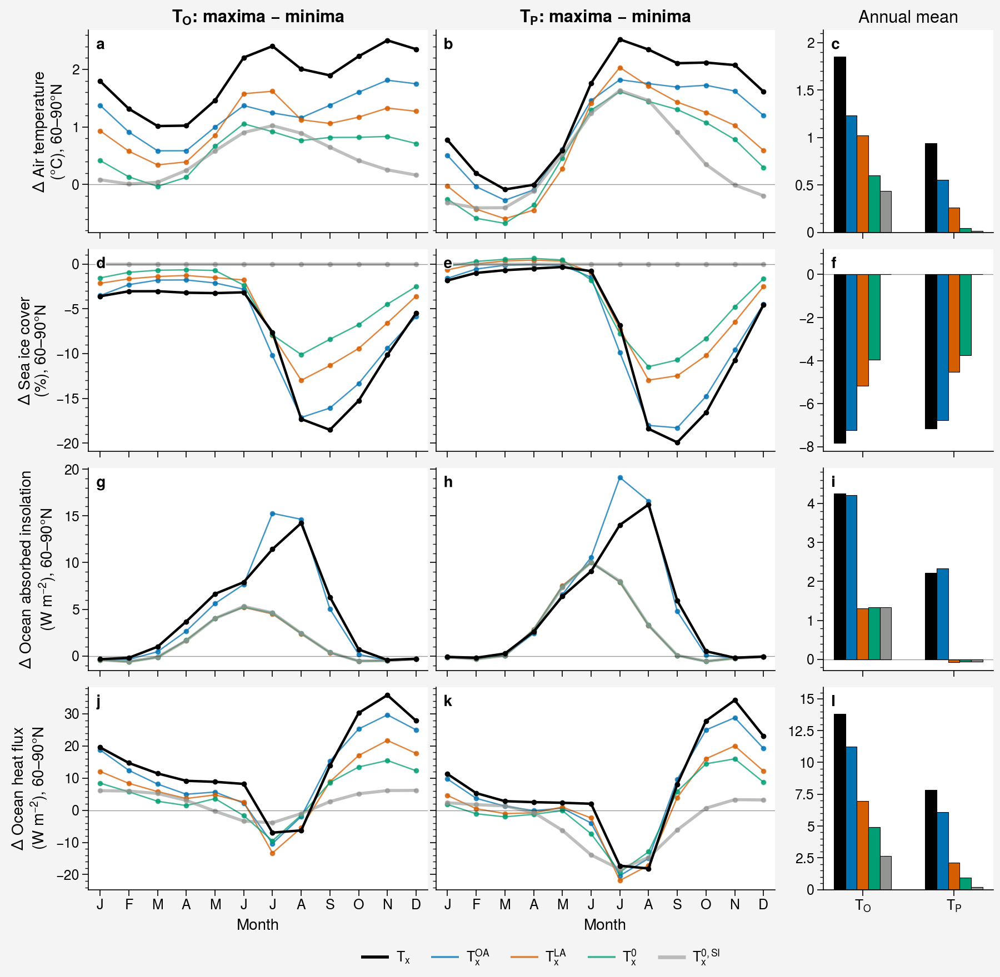

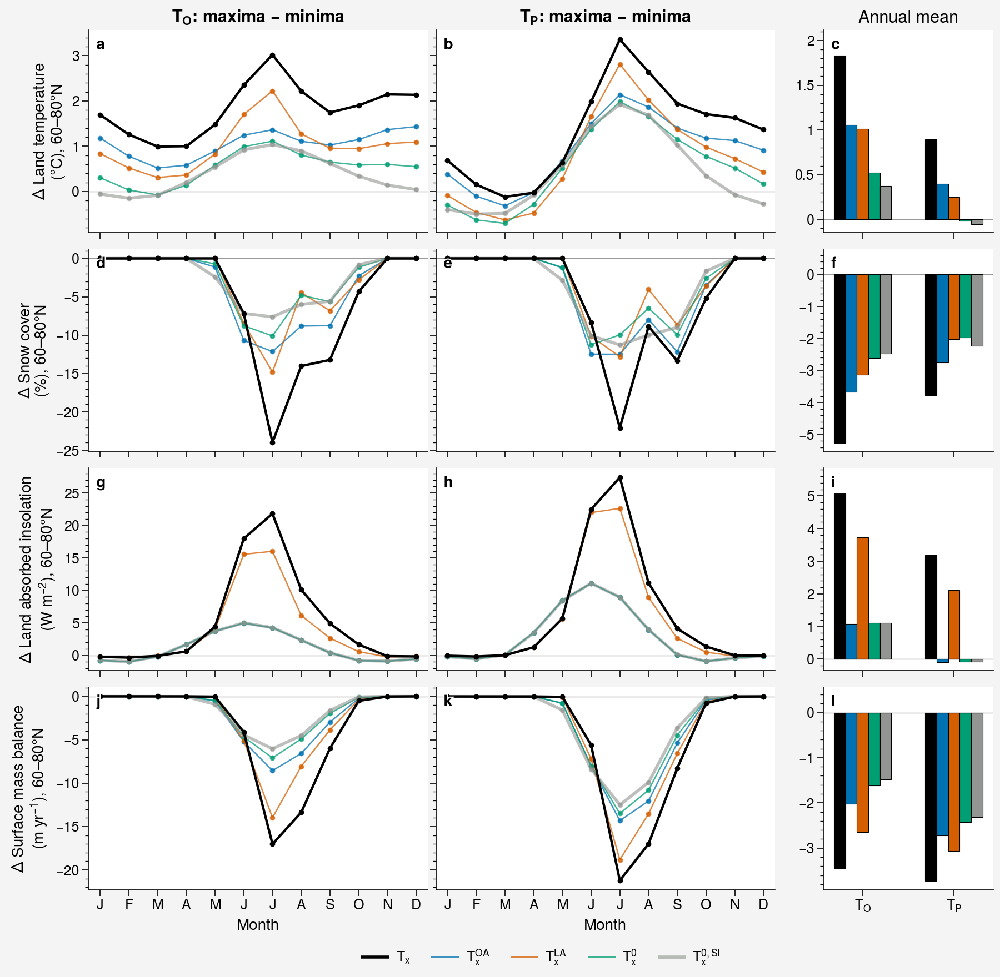

In [12]:
import numpy as np
import proplot as pplt
import matplotlib.axes as maxes
from matplotlib.lines import Line2D

# ---------------------------------------------------------------
# settings
# ---------------------------------------------------------------
mon, mlab = np.arange(12), list('JFMAMJJASOND')
ALL, JJA  = list(range(12)), [5, 6, 7]
GAP, HEADROOM = 1.4, 1.15

# (label, obliquity-only, precession-only, full run for area weights)
exps = [(r'$T_x$',                    preMPTo,      preMPTp,      preMPT),       # all feedbacks
        (r'$T_x^{\mathrm{OA}}$',      preMPTola,    preMPTpla,    preMPTla),     # ocean albedo varies, land prescribed
        (r'$T_x^{\mathrm{LA}}$',      preMPTooa,    preMPTpoa,    preMPToa),     # land albedo varies, ocean prescribed
        (r'$T_x^{0}$',                preMPToloa,   preMPTploa,   preMPTloa),    # both albedos prescribed
        (r'$T_x^{0,\mathrm{SI}}$',    preMPToloasi, preMPTploasi, preMPTloasi)]  # albedos and sea ice prescribed
LABS = [ex[0] for ex in exps]

STYLE = {r'$T_x$':                 dict(color='#000000', lw=1.6, alpha=1.0,  zorder=3),
         r'$T_x^{\mathrm{OA}}$':   dict(color='#0072B2', lw=0.9, alpha=0.75, zorder=2),
         r'$T_x^{\mathrm{LA}}$':   dict(color='#D55E00', lw=0.9, alpha=0.75, zorder=2),
         r'$T_x^{0}$':             dict(color='#009E73', lw=0.9, alpha=0.75, zorder=2),
         r'$T_x^{0,\mathrm{SI}}$': dict(color='gray',    lw=2, alpha=0.6, zorder=2)}

# key: (variable, y-label, (latmin, latmax), area key, scale)
# key: (variable, y-label, (latmin, latmax), area key, scale)
fields = {
    'Ta':   ('Ta',            'Air temperature\n(°C), 60–90°N',                     (60, 90), 'sarea',   1.0),
    'SI':   ('si_fraction',   'Sea ice cover\n(%), 60–90°N',                       (60, 90), 'oarea', 100.0),
    'SW':   ('rsdsnet_ocean', 'Ocean absorbed insolation\n(W m$^{-2}$), 60–90°N',  (60, 90), 'oarea',   1.0),
    'OHF':  ('ohf',           'Ocean heat flux\n(W m$^{-2}$), 60–90°N',            (60, 90), 'oarea',   1.0),
    'Tl':   ('Tl',            'Land temperature\n(°C), 60–80°N',                    (60, 80), 'larea',   1.0),
    'SC':   ('sc_fraction',   'Snow cover\n(%), 60–80°N',                          (60, 80), 'larea', 100.0),
    'LSW':  ('rsdsnet_land',  'Land absorbed insolation\n(W m$^{-2}$), 60–80°N',   (60, 80), 'larea',   1.0),
    'SMB':  ('smbp_rate',     'Surface mass balance\n(m yr$^{-1}$), 60–80°N',      (60, 80), 'larea',   1.0),
}
TOTALS = set()                             # all rates: monthly means, length-weighted annual means
BAR_MONTHS = {k: ALL for k in fields}
DAYS, ENERGY, AMOUNT = {'SFD'}, {'SWE', 'OHFE', 'LSWE'}, {'SMBM'}
TOTALS = DAYS | ENERGY | AMOUNT
BAR_MONTHS = {k: ALL for k in fields}      # e.g. BAR_MONTHS['Tl'] = JJA for a summer bar

# ---------------------------------------------------------------
# helpers
# ---------------------------------------------------------------
def box_monthly(e, ef, var, lmn, lmx, ar):
    """Area-weighted box mean of a monthly field, (kyr, 12)."""
    lat_f = np.asarray(ef.Var['lat']); area = np.asarray(ef.Var[ar])
    idx   = (lat_f > lmn) & (lat_f < lmx) & (area > 0)
    x     = np.asarray(getattr(e, var).monthly, float)[:, idx, :]
    return np.nansum(x * area[idx][None, :, None], axis=1) / np.nansum(area[idx])

def weighted_mean(e, xs, months):
    """Mean over the chosen months, weighted by paleo-calendar month length."""
    L = np.asarray(e.month_lengths['len'])[:, months]
    return np.sum(xs[:, months] * L, axis=1) / L.sum(axis=1)

def per_month(e, key, xs):
    """Convert a monthly mean into an amount per paleo-calendar month (states unchanged)."""
    L = np.asarray(e.month_lengths['len'])
    if key in DAYS:
        return (1 - xs) * L                        # snow-free days in each month
    if key in ENERGY:
        return xs * L * 86400 / 1e6                # W m-2 -> MJ m-2 in each month
    if key in AMOUNT:
        return xs * L / 365.2422                   # m yr-1 -> metres in each month
    return xs

def series_monthly(e, ef, key):
    """Monthly box series for a key, as a mean or as a per-month amount."""
    var, _, (lmn, lmx), ar, scale = fields[key]
    return per_month(e, key, box_monthly(e, ef, var, lmn, lmx, ar) * scale)

def annual_value(e, ef, key):
    """Annual total for accumulated amounts, length-weighted annual mean for states."""
    xs = series_monthly(e, ef, key)
    if key in TOTALS:
        return xs[:, BAR_MONTHS[key]].sum(axis=1)
    return weighted_mean(e, xs, BAR_MONTHS[key])

# ---------------------------------------------------------------
# panels
# ---------------------------------------------------------------
def monthly_panel(ax, key, col, pk, tr):
    for ex in exps:
        xs = series_monthly(ex[col], ex[3], key)
        ax.plot(mon, xs[pk].mean(0) - xs[tr].mean(0), marker='o', ms=2.5, **STYLE[ex[0]])
    ax.axhline(0, color='k', lw=0.5, alpha=0.4)

def bar_panel(ax, key):
    bw   = 0.88 / len(exps)
    offs = (np.arange(len(exps)) - (len(exps) - 1) / 2) * bw
    lo, hi = 0.0, 0.0
    for k, (col, pk, tr) in enumerate(((1, obl_peaks, obl_troughs), (2, pre_peaks, pre_troughs))):
        vals = []
        for i, ex in enumerate(exps):
            y = annual_value(ex[col], ex[3], key)
            d = y[pk].mean() - y[tr].mean()
            vals.append(d)
            maxes.Axes.bar(ax, k * GAP + offs[i], d, width=bw,
                           color=STYLE[ex[0]]['color'], edgecolor='k', lw=0.4)
        lo, hi = min(lo, min(vals)), max(hi, max(vals))
        print(f'{key:5s} {"obl" if k == 0 else "pre"}: ' +
              ', '.join(f'{l} {v:+.3g}' for l, v in zip(LABS, vals)))
    ax.axhline(0, color='k', lw=0.5, alpha=0.4)
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - 0.05 * span if lo < 0 else 0, hi + (HEADROOM - 1) * span)

def make_figure(keys, row_height=2.7, width=9.0):
    n = len(keys)
    shape = [[3*r + 1, 3*r + 1, 3*r + 2, 3*r + 2, 3*r + 3] for r in range(n)]
    fig, axs = pplt.subplots(shape, figsize=(width, row_height * n),
                             wspace=[0, 0.6, 0, 3.5], hspace=1.2, share=False)

    for r, key in enumerate(keys):
        last = r == n - 1
        ax_o, ax_p, ax_b = axs[3*r], axs[3*r + 1], axs[3*r + 2]
        monthly_panel(ax_o, key, 1, obl_peaks, obl_troughs)
        monthly_panel(ax_p, key, 2, pre_peaks, pre_troughs)
        lo = min(a.get_ylim()[0] for a in (ax_o, ax_p)); hi = max(a.get_ylim()[1] for a in (ax_o, ax_p))
        for a in (ax_o, ax_p):
            a.set_ylim(lo, hi)
            a.format(xlocator=mon, xminorlocator=[], xlim=(-0.4, 11.4),
                     xticklabels=mlab if last else [], xlabel='Month' if last else '')
        ax_o.format(ylabel=r'$\Delta$ ' + fields[key][1])
        ax_p.format(yticklabels=[])

        bar_panel(ax_b, key)
        ax_b.format(xlim=(-0.6, GAP + 0.6), xlocator=[0, GAP], xminorlocator=[],
                    xticklabels=['$T_O$', '$T_P$'] if last else [])
        if r == 0:
            ax_o.format(title='$T_O$: maxima − minima', titleweight='bold', titlesize=11)
            ax_p.format(title='$T_P$: maxima − minima', titleweight='bold', titlesize=11)
            ax_b.format(title='Annual mean', titlesize=11)

    handles = [Line2D([0], [0], color=STYLE[l]['color'], lw=STYLE[l]['lw'] + 0.4,
                      alpha=STYLE[l]['alpha']) for l in LABS]
    fig.legend(handles, LABS, loc='b', ncols=len(LABS), frameon=False, prop={'size': 9})
    axs.format(labelsize=10, ticklabelsize=9, abc=True, abcloc='ul', abcsize=10)
    for ax in axs:
        ax.spines[['top', 'right']].set_visible(False)
        ax.format(grid=False)
    return fig
# ---------------------------------------------------------------
# figures
# ---------------------------------------------------------------
figA = make_figure(['Ta', 'SI', 'SW', 'OHF'],row_height=2.2)       # sea ice route
figA.save('f06.png', dpi=300)
figA.save('f09.pdf', dpi=300)

figB = make_figure(['Tl', 'SC', 'LSW', 'SMB'],row_height=2.2)      # land route
figB.save('f07.png', dpi=300)
figB.save('f07.pdf', dpi=300)

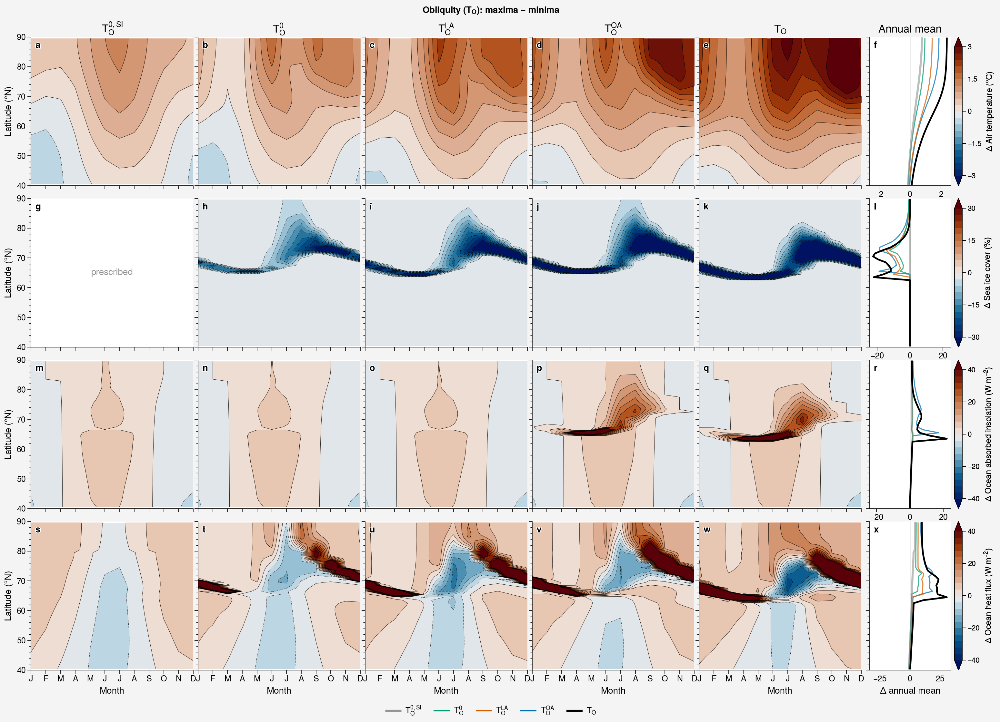

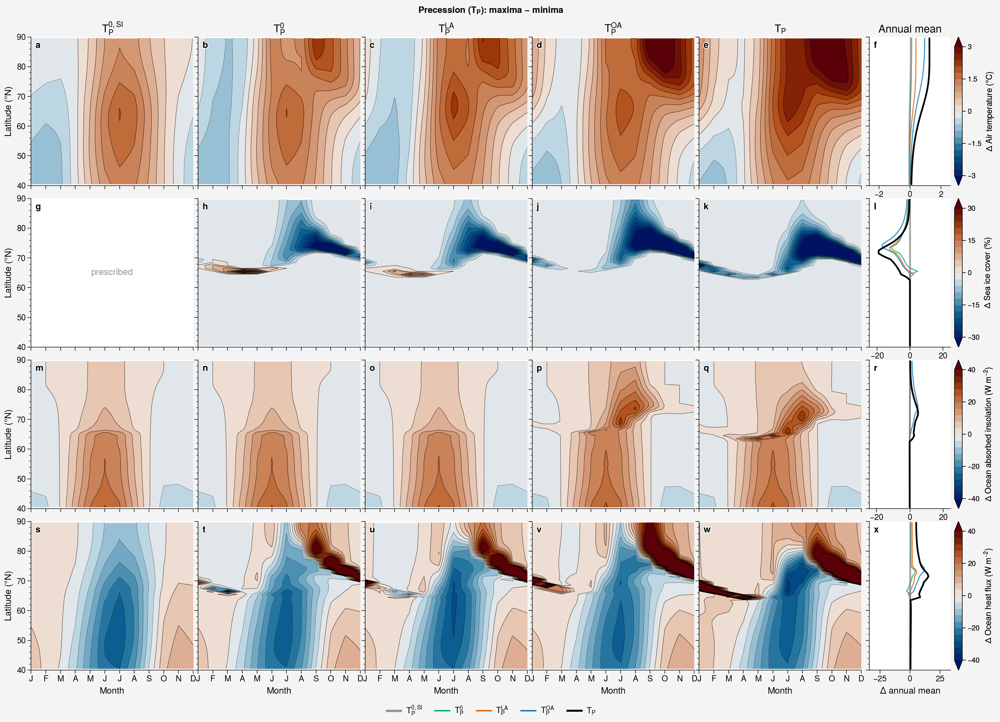

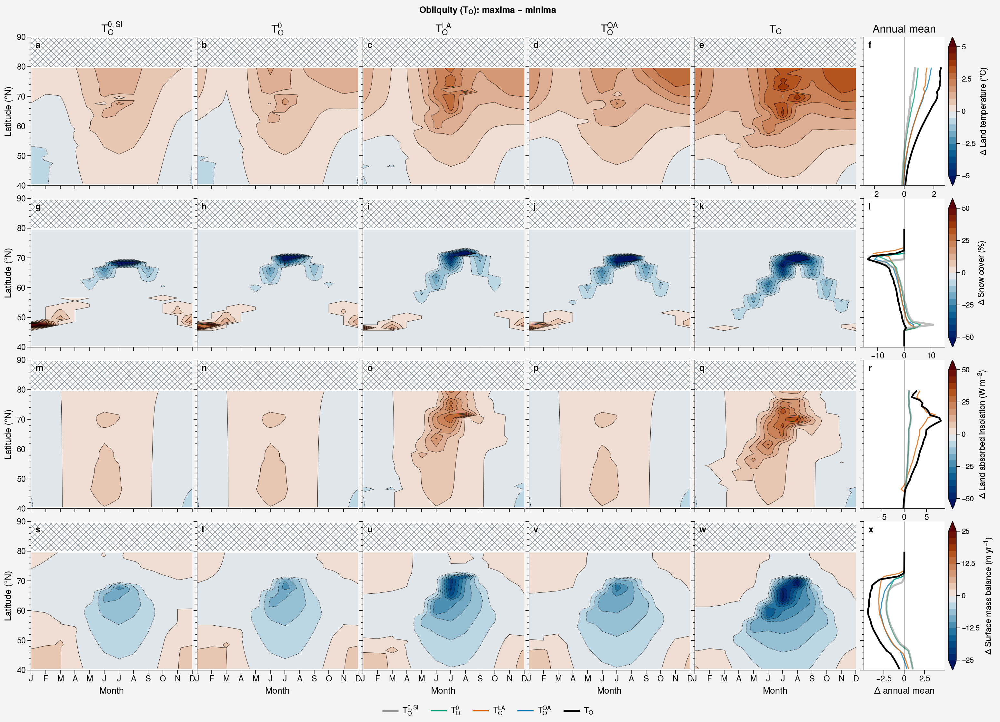

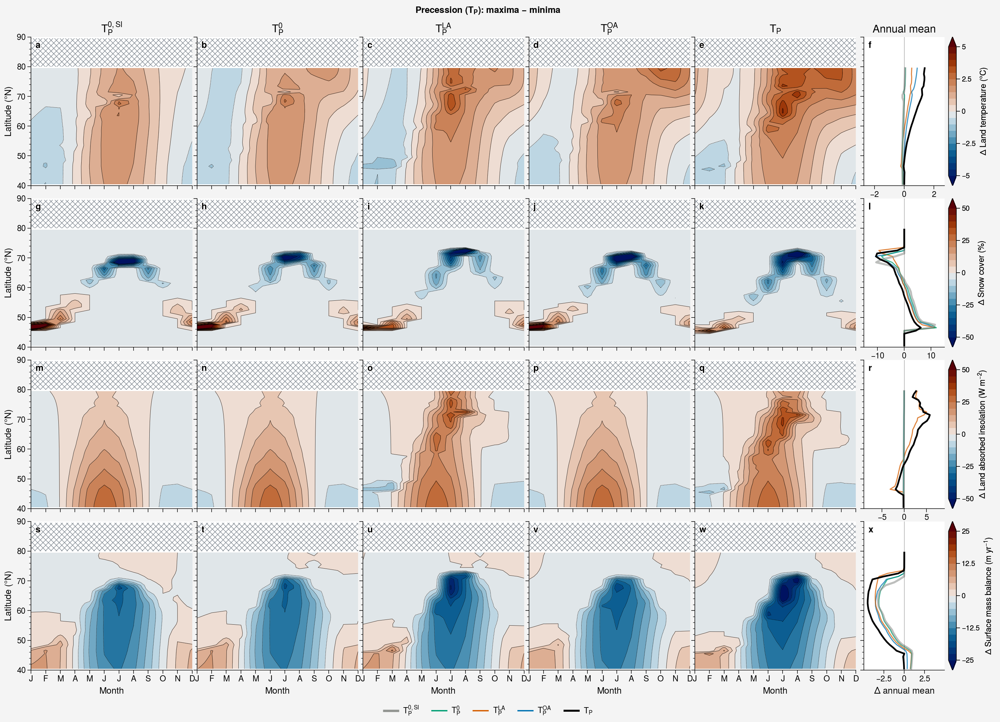

In [13]:
import numpy as np
import proplot as pplt
from matplotlib.lines import Line2D

# ---------------------------------------------------------------
# settings
# ---------------------------------------------------------------
LATMIN, LATMAX, N_LEVELS = 40, 90, 21
months = np.arange(12)
mlab   = list('JFMAMJJASOND')

# (variable, label, colour range or None for automatic, scale, area key for masking)
VARS = {
    'ocean': [('Ta',            'Air temperature (°C)',                   3,    1.0, 'sarea'),
              ('si_fraction',   'Sea ice cover (%)',                     30, 100.0, 'oarea'),
              ('rsdsnet_ocean', 'Ocean absorbed\ninsolation (W m$^{-2}$)', 40,  1.0, 'oarea'),
              ('ohf',           'Ocean heat flux (W m$^{-2}$)',          40,   1.0, 'oarea')],
    'land':  [('Tl',            'Land temperature (°C)',                  None, 1.0, 'larea'),
              ('sc_fraction',   'Snow cover (%)',                        None, 100.0, 'larea'),
              ('rsdsnet_land',  'Land absorbed\ninsolation (W m$^{-2}$)', None, 1.0, 'larea'),
              ('smbp_rate',     'Surface mass balance (m yr$^{-1}$)',    None, 1.0, 'larea')],
}
# mean-state contour drawn on each panel: (variable, level)
EDGE = {'ocean': ('si_fraction', 0.15), 'land': ('sc_fraction', 0.5)}

ref     = exps[0][3]
lat_all = np.asarray(ref.Var['lat'])
lati    = np.where((lat_all >= LATMIN) & (lat_all <= LATMAX))[0]
lat     = lat_all[lati]

ORB = {'obl': (1, obl_peaks, obl_troughs, 'O'), 'pre': (2, pre_peaks, pre_troughs, 'P')}

def mask(ar):
    """True where the surface type exists, (lat,)."""
    return np.asarray(ref.Var[ar])[lati] > 0

def composite(e, v, scale, pk, tr, ar):
    """(lat, 12) mean over orbital maxima minus mean over minima, masked to the surface."""
    mon = np.asarray(getattr(e, v).monthly, float)[:, lati, :]
    d   = (mon[pk].mean(0) - mon[tr].mean(0)) * scale
    return np.where(mask(ar)[:, None], d, np.nan)

def ann_composite(e, v, scale, pk, tr, ar):
    """(lat,) annual-mean maxima minus minima, masked to the surface."""
    ann = np.asarray(getattr(e, v).annual, float)[:, lati]
    d   = (ann[pk].mean(0) - ann[tr].mean(0)) * scale
    return np.where(mask(ar), d, np.nan)

def mean_state(e, v):
    return np.asarray(getattr(e, v).monthly, float)[:, lati, :].mean(0)

def nice(x):
    """Round a positive number up to 1, 2, 2.5 or 5 times a power of ten."""
    p = 10 ** np.floor(np.log10(x))
    for f in (1, 2, 2.5, 5, 10):
        if x <= f * p:
            return f * p

def colour_range(v, scale, ar, rng):
    if rng is not None:
        return rng
    vals = [np.nanpercentile(np.abs(composite(ex[col], v, scale, pk, tr, ar)), 98)
            for col, pk, tr, _ in ORB.values() for ex in exps]
    mx = np.nanmax(vals)
    return nice(mx) if np.isfinite(mx) and mx > 0 else 1.0

def prof_limit(v, scale, ar):
    """Symmetric x-limit for the annual profile, shared by both orbits."""
    mx = max(np.nanmax(np.abs(ann_composite(ex[col], v, scale, pk, tr, ar)))
             for col, pk, tr, _ in ORB.values() for ex in exps)
    return 1.1 * mx if np.isfinite(mx) and mx > 0 else 1.0

# ---------------------------------------------------------------
# figure: rows = variables, columns = experiments + annual profile
# ---------------------------------------------------------------
def appendix_figure(orb='obl', domain='ocean', overlay=True):
    col, pk, tr, sub = ORB[orb]
    rows = VARS[domain]
    nv, ne = len(rows), len(exps)
    order  = exps[::-1]    
    fig, axs = pplt.subplots(nrows=nv, ncols=ne + 1, figsize=(15.5, 2.8 * nv),
                             wratios=[1] * ne + [0.5], share=False,
                             wspace=[0.6] * (ne - 1) + [1.0], hspace=1.6)

    for r, (v, vlab, rng, scale, ar) in enumerate(rows):
        rng    = colour_range(v, scale, ar, rng)
        levels = np.linspace(-rng, rng, N_LEVELS)
        m, last = None, r == nv - 1

        # --- latitude-month contours ---
        for c, ex in enumerate(order):
            ax, e = axs[r, c], ex[col] 
    
            d = composite(e, v, scale, pk, tr, ar)

            if np.allclose(np.nan_to_num(d), 0):           # prescribed field, e.g. sea ice in T^{0,SI}
                ax.text(0.5, 0.5, 'prescribed', transform=ax.transAxes,
                        ha='center', va='center', color='gray', size=10)
            else:
                mm = ax.contourf(months, lat, d, cmap='vik', levels=levels, extend='both')
                ax.contour(months, lat, d, levels=levels, colors='k', linewidths=0.3)
                m = m or mm

            # hatch latitudes where this surface type doesn't exist (as in f08)
            missing = (~mask(ar)).astype(float)
            if missing.any():
                ax.contourf(months, lat, np.repeat(missing[:, None], 12, axis=1), levels=[0.5, 1.5],
                            colors='none', hatches=['xxxx'], zorder=1)

            if overlay:                                     # mean sea ice edge or snow line
                ev, lev = EDGE[domain]
                try:
                    ax.contour(months, lat, mean_state(e, ev), levels=[lev],
                               colors='k', linewidths=1.0, linestyles='--')
                except (AttributeError, ValueError):
                    pass

            ax.format(xlim=(0, 11), xlocator=months, xminorlocator=[],
                      xticklabels=mlab if last else [], xlabel='Month' if last else '',
                      ylim=(LATMIN, LATMAX), ylocator=np.arange(LATMIN, LATMAX + 1, 10),
                      ylabel='Latitude (°N)' if c == 0 else '',
                      yticklabels=None if c == 0 else [])
            if r == 0:
                ax.format(title=ex[0].replace('T_x', f'T_{sub}'), titlesize=12)

        # --- annual-mean profile ---
        axp = axs[r, ne]
        for ex in exps:
            st = STYLE[ex[0]]
            axp.plot(ann_composite(ex[col], v, scale, pk, tr, ar), lat,
                     color=st['color'], lw=st['lw'] + 0.3, alpha=st['alpha'], zorder=st['zorder'])
        axp.axvline(0, color='k', lw=0.5, alpha=0.4)
        lim = prof_limit(v, scale, ar)
        axp.format(xlim=(-lim, lim), ylim=(LATMIN, LATMAX),
                   ylocator=np.arange(LATMIN, LATMAX + 1, 10), yticklabels=[], ylabel='',
                   xlabel=r'$\Delta$ annual mean' if last else '', xminorlocator=[])
        if r == 0:
            axp.format(title='Annual mean', titlesize=12)

        if m is not None:
            cb = axp.colorbar(m, loc='r', width=0.12, ticks=levels[::5])
            cb.set_label(r'$\Delta$ ' + vlab.replace('\n', ' '), size=9)
            cb.ax.tick_params(labelsize=8)

    handles = [Line2D([0], [0], color=STYLE[ex[0]]['color'], lw=STYLE[ex[0]]['lw'] + 0.6)
               for ex in order]                             # lines 137–139, legend
    fig.legend(handles, [ex[0].replace('T_x', f'T_{sub}') for ex in order],
               loc='b', ncols=ne, frameon=False, prop={'size': 9})

    name = 'Obliquity' if orb == 'obl' else 'Precession'
    axs.format(abc=True, abcloc='ul', abcsize=10, labelsize=10, ticklabelsize=9, grid=False,
               suptitle=f'{name} ($T_{sub}$): maxima − minima')
    for ax in axs:
        ax.spines[['top', 'right']].set_visible(False)
    return fig

# ---------------------------------------------------------------
# the four supplementary figures
# ---------------------------------------------------------------
for domain, tag in (('ocean', 'S1'), ('land', 'S2')):
    for orb, k in (('obl', 'a'), ('pre', 'b')):
        fig = appendix_figure(orb, domain, overlay=False)
        fig.save(f'f{tag}{k}_{domain}_{orb}.png', dpi=300)
        fig.save(f'f{tag}{k}_{domain}_{orb}.pdf', dpi=300)


## Additional Analysis

run             slope o  slope p   o/p  r2 o  r2 p   dT o   dT p   o/p
$T_x$            0.1182   0.0570  2.07  1.00  0.94   2.53   2.75  0.92
$T_x^{\mathrm{OA}}$   0.0578   0.0385  1.50  1.00  1.00   1.24   1.86  0.67
$T_x^{\mathrm{LA}}$   0.0804   0.0462  1.74  1.00  0.96   1.73   2.23  0.78
$T_x^{0}$        0.0450   0.0350  1.29  1.00  1.00   0.97   1.69  0.57
$T_x^{0,\mathrm{SI}}$   0.0443   0.0349  1.27  1.00  0.99   0.95   1.69  0.56


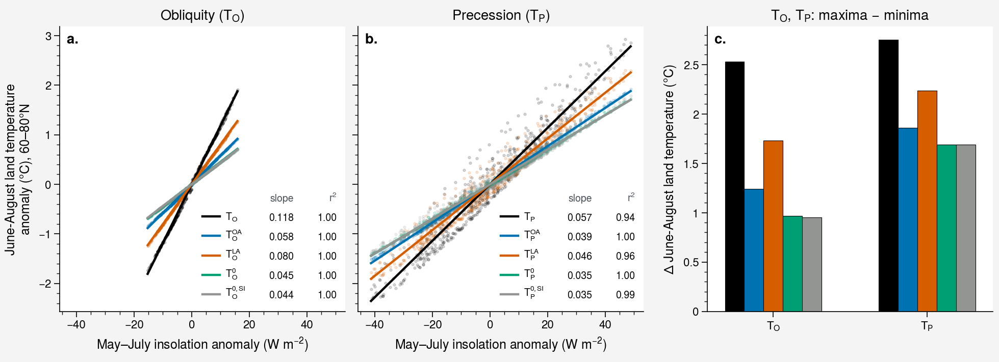

In [14]:
import numpy as np
import proplot as pplt
import matplotlib.axes as maxes

# ---------------------------------------------------------------
# settings
# ---------------------------------------------------------------
tvar, (lmn, lmx), ar = 'Tl', (60, 80), 'larea'
MJJ, JJA = [4, 5, 6], [5, 6, 7]
GAP = 1.4

# (superscript, obliquity-only, precession-only, full run for area weights, colour)
runs = [(None,              preMPTo,      preMPTp,      preMPT,      '#000000'),   # all feedbacks
        (r'\mathrm{OA}',    preMPTola,    preMPTpla,    preMPTla,    '#0072B2'),   # ocean albedo varies
        (r'\mathrm{LA}',    preMPTooa,    preMPTpoa,    preMPToa,    '#D55E00'),   # land albedo varies
        ('0',               preMPToloa,   preMPTploa,   preMPTloa,   '#009E73'),   # both albedos prescribed
        (r'0,\mathrm{SI}',  preMPToloasi, preMPTploasi, preMPTloasi, 'gray')]      # albedos and sea ice prescribed
EXT = {'obl': (obl_peaks, obl_troughs), 'pre': (pre_peaks, pre_troughs)}
SUB = {'obl': 'O', 'pre': 'P'}

def label(sup, orb):
    s = SUB[orb]
    return f'$T_{s}$' if sup is None else f'$T_{s}^{{{sup}}}$'

def box_monthly(e, ef, var):
    lat_f = np.asarray(ef.Var['lat']); area = np.asarray(ef.Var[ar])
    idx = (lat_f > lmn) & (lat_f < lmx) & (area > 0)
    x = np.asarray(getattr(e, var).monthly, float)[:, idx, :]
    return np.nansum(x * area[idx][None, :, None], axis=1) / np.nansum(area[idx])

def wmean(e, xs, months):
    L = np.asarray(e.month_lengths['len'])[:, months]
    return np.sum(xs[:, months] * L, axis=1) / L.sum(axis=1)
def stats_table(ax, rows, x0=0.50, xs=0.82, xr=0.97, y0=0.04, dy=0.068, fs=7):
    
    """Legend as an aligned table in the lower right: line, label, slope, r2."""
    n = len(rows)
    yh = y0 + n * dy
    ax.text(xs, yh, 'slope', transform=ax.transAxes, ha='right', va='bottom', fontsize=fs, color='gray7')
    ax.text(xr, yh, '$r^2$', transform=ax.transAxes, ha='right', va='bottom', fontsize=fs, color='gray7')
    for i, (lab, s, r2, c) in enumerate(rows):
        y = y0 + (n - 1 - i) * dy
        maxes.Axes.plot(ax, [x0, x0 + 0.06], [y + 0.3 * dy] * 2, transform=ax.transAxes,
                        color=c, lw=1.6, clip_on=False)
        ax.text(x0 + 0.08, y, lab,       transform=ax.transAxes, ha='left',  va='bottom', fontsize=fs)
        ax.text(xs,        y, f'{s:.3f}',  transform=ax.transAxes, ha='right', va='bottom', fontsize=fs)
        ax.text(xr,        y, f'{r2:.2f}', transform=ax.transAxes, ha='right', va='bottom', fontsize=fs)

# ---------------------------------------------------------------
# figure: scatter (obl) | scatter (pre) | bars of maxima - minima
# ---------------------------------------------------------------
fig, axs = pplt.subplots([[1, 2, 3]], wratios=(1, 1, 1), refwidth=2.8,
                         share=False, wspace=(1.0, 5.0))
S, D = {}, {}
xlo = ylo = np.inf; xhi = yhi = -np.inf
for col, orb in enumerate(('obl', 'pre')):
    ax = axs[col]
    pk, tr = EXT[orb]
    rows = []
    for i, (sup, eo, ep, ef, c) in enumerate(runs):
        e  = (eo, ep)[col]
        x  = wmean(e, box_monthly(e, ef, 'I'), MJJ)
        y  = wmean(e, box_monthly(e, ef, tvar), JJA)
        xa, ya = x - x.mean(), y - y.mean()
        p  = np.polyfit(xa, ya, 1)
        r2 = np.corrcoef(xa, ya)[0, 1] ** 2
        S[(orb, i)] = (p[0], r2)
        D[(orb, i)] = y[pk].mean() - y[tr].mean()
        ax.scatter(xa, ya, s=3, alpha=0.15, color=c, zorder=1)
        xx = np.array([xa.min(), xa.max()])
        maxes.Axes.plot(ax, xx, np.polyval(p, xx), color=c, lw=1.6, zorder=3)
        rows.append((label(sup, orb), p[0], r2, c))
        xlo, xhi = min(xlo, xa.min()), max(xhi, xa.max())
        ylo, yhi = min(ylo, ya.min()), max(yhi, ya.max())
    stats_table(ax, rows)
    ax.format(title=f'Obliquity ($T_O$)' if orb == 'obl' else f'Precession ($T_P$)',
              xlabel='May–July insolation anomaly (W m$^{-2}$)',
              ylabel='June-August land temperature\nanomaly (°C), 60–80°N' if col == 0 else '',
              yticklabels=None if col == 0 else [], grid=False)

xpad, ypad = 0.05 * (xhi - xlo), 0.05 * (yhi - ylo)
for ax in axs[:2]:
    ax.set_xlim(xlo - xpad, xhi + xpad)
    ax.set_ylim(ylo - ypad, yhi + ypad)

# bars: JJA land temperature, orbital maxima minus minima
axb = axs[2]
bw   = 0.88 / len(runs)
offs = (np.arange(len(runs)) - (len(runs) - 1) / 2) * bw
for k, orb in enumerate(('obl', 'pre')):
    for i, (*_, c) in enumerate(runs):
        maxes.Axes.bar(axb, k * GAP + offs[i], D[(orb, i)], width=bw,
                       color=c, edgecolor='k', lw=0.4)
axb.axhline(0, color='k', lw=0.5, alpha=0.4)
axb.format(xlim=(-0.6, GAP + 0.6), xlocator=[0, GAP], xticklabels=['$T_O$', '$T_P$'],
           xminorlocator=[], ylabel=r'$\Delta$ June-August land temperature (°C)',
           title='$T_O$, $T_P$: maxima − minima', grid=False)

for ax in axs:
    ax.spines[['top', 'right']].set_visible(False)
axs.format(abc='a.', abcloc='ul', labelsize=9, ticklabelsize=8)
fig.save('f09.png', dpi=300)
fig.save('f09.pdf', dpi=300)

# ---------------------------------------------------------------
# table
# ---------------------------------------------------------------
print(f'{"run":14s}{"slope o":>9s}{"slope p":>9s}{"o/p":>6s}{"r2 o":>6s}{"r2 p":>6s}'
      f'{"dT o":>7s}{"dT p":>7s}{"o/p":>6s}')
for i, (sup, *_) in enumerate(runs):
    so, ro = S[('obl', i)]; sp, rp = S[('pre', i)]
    do, dp = D[('obl', i)], D[('pre', i)]
    print(f'{label(sup, "obl").replace("_O", "_x"):14s}{so:9.4f}{sp:9.4f}{so/sp:6.2f}{ro:6.2f}{rp:6.2f}'
          f'{do:7.2f}{dp:7.2f}{do/dp:6.2f}')



# LIG

In [15]:
import pandas as pd

# Latitude
lig127k_lat = np.arange(-89.5,89.5+1,1)

# Sea-ice data
# ============

# Last Interglacial (LIG)
LIG_SIA        = pd.read_csv('LIG_SIA.txt',skipinitialspace=True,header=0, delimiter=';')
LIG_SIA_max    = pd.concat([pd.Series(['max']), LIG_SIA.iloc[:,1:].max(axis=0)])
LIG_SIA_min    = pd.concat([pd.Series(['min']), LIG_SIA.iloc[:,1:].min(axis=0)])
LIG_SIA.loc[len(LIG_SIA.index)] = LIG_SIA_max
LIG_SIA.iloc[17,0]='MAX'
LIG_SIA.loc[len(LIG_SIA.index)] = LIG_SIA_min
LIG_SIA.iloc[18,0]='MIN'

# Last Interglacial minus Pre-Industrial (LIG_PI)
LIG_PI_SIA     = pd.read_csv('LIG-PI_SIA.txt',skipinitialspace=True,header=0, delimiter=';')
LIG_PI_SIA_max = pd.concat([pd.Series(['max']), LIG_PI_SIA.iloc[:,1:].max(axis=0)])
LIG_PI_SIA_min = pd.concat([pd.Series(['min']), LIG_PI_SIA.iloc[:,1:].min(axis=0)])
LIG_PI_SIA.loc[len(LIG_PI_SIA.index)] = LIG_PI_SIA_max
LIG_PI_SIA.iloc[17,0]='MAX'
LIG_PI_SIA.loc[len(LIG_PI_SIA.index)] = LIG_PI_SIA_min
LIG_PI_SIA.iloc[18,0]='MIN'

# Zonal-Mean Temperature
# ======================

# Last Interglacial minus Pre-Industrial (LIG_PI)
LIG_PI_Ta   = pd.read_csv('PMIP4_lig127k_diff_zonal_1_tas_ann.csv',skipinitialspace=True,header=0)
maxValues   = LIG_PI_Ta.iloc[:,1:].max(axis=1)
minValues   = LIG_PI_Ta.iloc[:,1:].min(axis=1)
medValues   = LIG_PI_Ta.iloc[:,1:].median(axis=1)
avgValues   = LIG_PI_Ta.iloc[:,1:].mean(axis=1)
LIG_PI_Ta['max'] = maxValues
LIG_PI_Ta['min'] = minValues
LIG_PI_Ta['med'] = medValues

In [16]:
LIG_PI_Ta

,Unnamed: 0,ACCESS-ESM1-5,AWI-ESM-1-1-LR,AWI-ESM-2-1-LR,CESM2,CNRM-CM6-1,EC-Earth3-LR,FGOALS-f3-L,FGOALS-g3,GISS-E2-1-G,...,IPSL-CM6A-LR,MIROC-ES2L,MPI-ESM1-2-LR,NESM3,NorESM1-F,NorESM2-LM,average,max,min,med
0,0,0.869361,0.499530,-0.299059,0.149640,0.883400,-0.206352,-0.107482,0.676195,-0.512623,...,0.229704,0.342419,0.382023,1.040092,-0.543107,0.279575,0.261876,1.040092,-0.543107,0.282195
1,1,0.872940,0.498244,-0.296690,0.139038,0.887250,-0.185111,-0.136149,0.711430,-0.488643,...,0.190811,0.342419,0.379716,1.041038,-0.517584,0.294159,0.264283,1.041038,-0.517584,0.279221
2,2,0.928521,0.480427,-0.263914,0.133593,0.894272,-0.157939,-0.199515,0.746642,-0.440705,...,0.156769,0.324973,0.347791,1.054160,-0.446064,0.313251,0.269310,1.054160,-0.446064,0.291281
3,3,0.989522,0.472433,-0.217516,0.135003,0.852431,-0.134456,-0.246313,0.781851,-0.398531,...,0.107941,0.277088,0.330059,1.066116,-0.344597,0.335277,0.275697,1.066116,-0.398531,0.276393
4,4,1.013593,0.498696,-0.123625,0.148637,0.833321,-0.111876,-0.271150,0.817080,-0.362123,...,0.059059,0.229204,0.361828,1.074007,-0.301269,0.356172,0.286799,1.074007,-0.362123,0.258002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,175,2.495213,-0.408747,0.464426,1.301854,1.771843,3.663073,0.499596,4.528559,1.529294,...,1.343508,0.229772,0.414188,1.014221,0.925941,0.940752,1.622409,6.478124,-0.408747,1.158038
176,176,2.524928,-0.416873,0.449170,1.281870,1.779374,3.570842,0.522680,4.743654,1.525324,...,1.308126,0.236436,0.389353,1.072841,0.924373,0.963897,1.632302,6.502286,-0.416873,1.177355
177,177,2.548916,-0.426851,0.426860,1.263208,1.781519,3.473385,0.541755,4.958629,1.540049,...,1.298757,0.243099,0.373060,1.141787,0.911358,0.980660,1.643850,6.505851,-0.426851,1.202497
178,178,2.546292,-0.437358,0.402530,1.248910,1.763431,3.388228,0.568348,5.173616,1.573498,...,1.278336,0.245527,0.359217,1.213688,0.903725,0.994157,1.656242,6.502024,-0.437358,1.231299


In [17]:
version = 'moist'
res = 1.0
# Last Interglacial
with open( f"../output/output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    lig_data = pickle.load(file)['ligStateYear']

with open( f"../output/output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    Var = pickle.load(file)['Var'] 
    
# Pre-Industrial
with open( f"../output/output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    pi_data = pickle.load(file)['piStateYear']  

# constants
with open( f"../output/output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    var = pickle.load(file)['Var'] 

# LIG insolation
with open( f"../output/output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    lig_inso = pickle.load(file)['ligI']['ligI'] 

# PI insolation
with open( f"../output/output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    pi_inso = pickle.load(file)['piI']['ligI'] 

#### ___Apply paleo-calendar effect___

In [18]:
# ================================
# Orbital parameter configurations
# ================================

# pre-industrial
orb_pi  = {'pre': np.deg2rad(100.33+180), 'obl': np.deg2rad(23.459), 'ecc': 0.016764}

# last interglacial
orb_lig = {'pre': np.deg2rad(275.41+180), 'obl': np.deg2rad(24.040),'ecc': 0.039378}

# ===================================
# Calculate start and end month dates
# ===================================

pi_rmonlen, pi_rmonbeg, _, pi_rmonend, _ = get_month_lengths(orb_pi['ecc'], orb_pi['pre'] % (2 * np.pi), orb_pi['ecc'], orb_pi['pre'] % (2 * np.pi))

lig_rmonlen, lig_rmonbeg, _, lig_rmonend, _ = get_month_lengths(orb_lig['ecc'], orb_lig['pre'] % (2 * np.pi), orb_pi['ecc'], orb_pi['pre'] % (2 * np.pi))

# ============================================================
# Calculate paleo-corrected monthly averages from daily fields 
# ============================================================

ndays = 365

# sea ice area -- northern hemisphere
si_area_lig = (lig_data['si_fraction']*Var['oarea'][:,None]) # sea ice area (lat, day)
si_area_pi = (pi_data['si_fraction']*Var['oarea'][:,None])   # sea ice area (lat, day)
nhi = np.where(Var['lat'] > 0.)[0]                           # index for NH
si_area_nh_lig = np.nansum(si_area_lig[nhi], axis = 0)           # NH sea ice area (day)
si_area_nh_pi = np.nansum(si_area_pi[nhi], axis = 0)            # NH sea ice area (day)

zemba_lig_sic_nh = day_to_rmon_ts_2d(ndays, lig_rmonbeg, lig_rmonend, si_area_nh_lig[None,:]).squeeze()
zemba_pi_sic_nh = day_to_rmon_ts_2d(ndays, pi_rmonbeg, pi_rmonend, si_area_nh_pi[None,:]).squeeze()
zemba_lig_pi_sic_nh = zemba_lig_sic_nh - zemba_pi_sic_nh

# insolation -- for all latitudes
lig_inso_monthly = np.zeros((lig_inso.shape[1], 12))
pi_inso_monthly = np.zeros((pi_inso.shape[1], 12))
lig_inso_monthly = day_to_rmon_ts_2d(ndays, lig_rmonbeg, lig_rmonend, lig_inso)
pi_inso_monthly = day_to_rmon_ts_2d(ndays, pi_rmonbeg, pi_rmonend, pi_inso)

# temperature -- for all latitudes
pi_ta = pi_data['Ta']
lig_ta = lig_data['Ta']
lig_ta_monthly = np.zeros((lig_ta.shape[1], 12))
pi_ta_monthly = np.zeros((pi_ta.shape[1], 12))
lig_ta_monthly = day_to_rmon_ts_2d(ndays, lig_rmonbeg, lig_rmonend, lig_ta)
pi_ta_monthly = day_to_rmon_ts_2d(ndays, pi_rmonbeg, pi_rmonend, pi_ta)

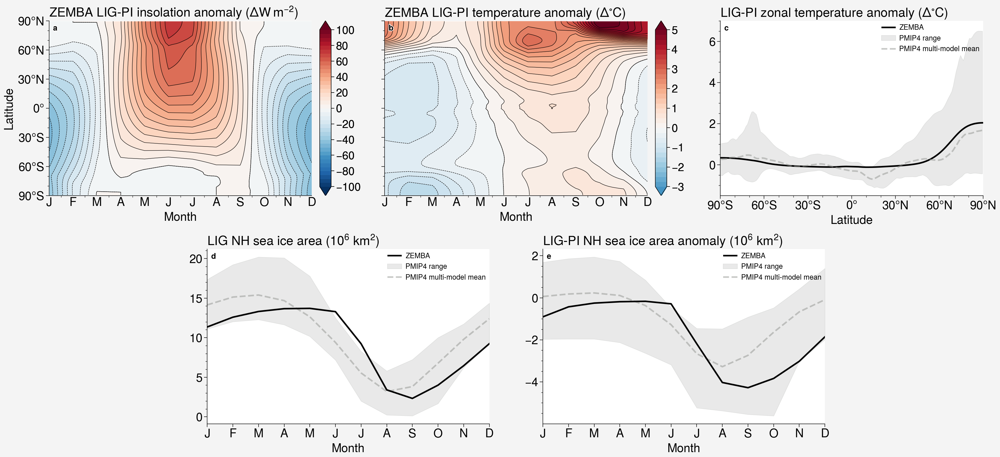

In [19]:
# Plot comparision of insolation, temperature and sea ice
# =======================================================

# define figure
shape = [[1,1,2,2,3,3],
         [0,4,4,5,5,0],]
fig, axs = pplt.subplots(shape, figsize=(17.5,8), sharex=False, sharey=False, space=7.5, abc=True, abcloc='ul', grid=False)

# insolation anomaly
months, lats = np.meshgrid(np.arange(1, 13, 1), var["lat"])
c=axs[0].contourf(months, lats, lig_inso_monthly - pi_inso_monthly, extend = 'both', levels = np.arange(-100,100+5,5))
axs[0].contour(months, lats, lig_inso_monthly - pi_inso_monthly, levels = np.arange(0,100+5,5), ls = 'solid', color = 'black', lw = 0.5)
axs[0].contour(months, lats, lig_inso_monthly - pi_inso_monthly, levels = np.arange(-100,0+5,5), ls = 'dashed', color = 'black', lw = 0.5)

cb=axs[0].colorbar(c, loc='r', ticks= np.arange(-100,100+20,20))
cb.ax.tick_params(labelsize=14) 

# temperature anomaly
c=axs[1].contourf(months, lats, lig_ta_monthly-pi_ta_monthly, extend = 'both', levels = np.arange(-3,5+0.25,0.25))
axs[1].contour(months, lats, lig_ta_monthly-pi_ta_monthly, levels = np.arange(0,5+0.25,0.25), ls = 'solid', color = 'black', lw = 0.5)
axs[1].contour(months, lats, lig_ta_monthly-pi_ta_monthly, levels = np.arange(-3,0+0.25,0.25), ls = 'dashed', color = 'black', lw = 0.5)

cb=axs[1].colorbar(c, loc='r', ticks= np.arange(-5,5+1,1))
cb.ax.tick_params(labelsize=14) 

# zonal mean LIG-PI versus CMIP6 Ensemble
l1=axs[2].plot(var['lat'], lig_data['Ta'].mean(axis=1)-pi_data['Ta'].mean(axis=1), color = 'black', lw = 2)
# test for other
axs[2].format(ylim=(-1.5, 7), xlabel = 'Latitude')
l2=axs[2].plot(lig127k_lat, LIG_PI_Ta['average'],color='grey',alpha=0.5,lw=2,linestyle='dashed',label='MMM')
#axs[2].plot(lat,data['med'],color='grey',alpha=0.5,lw=2,linestyle='dashed',label='MMM')
l3=axs[2].fill_between(lig127k_lat, LIG_PI_Ta['max'], LIG_PI_Ta['min'],color='grey',alpha=0.2)
axs[2].legend(handles=[l1, l3, l2], labels = ['ZEMBA', 'PMIP4 range',  'PMIP4 multi-model mean'], ncols=1, loc='ur', frameon=False)
axs[2].yaxis.label.set_visible(False)

# Last Interglacial Sea Ice
axs[3].plot(np.arange(1, 12+1), LIG_SIA.iloc[16,1:13],color='grey',alpha=0.5,lw=2,linestyle='dashed')
g=np.array(LIG_SIA.iloc[17,1:13].to_numpy(), dtype=float)
g1=np.array(LIG_SIA.iloc[18,1:13].to_numpy(), dtype=float)
axs[3].fill_between(np.arange(1, 12+1), g, g1,color='grey',alpha=0.2)
axs[3].plot(np.arange(1, 12+1), zemba_lig_sic_nh*1e-12,color='black',alpha=1,lw=2,linestyle='solid')
axs[3].legend(handles=[l1, l3, l2], labels = ['ZEMBA', 'PMIP4 range',  'PMIP4 multi-model mean'], ncols=1, loc='ur', frameon=False)
axs[3].yaxis.label.set_visible(False)

# Last Interglacial minus Pre-Industrial Sea Ice
axs[4].plot(np.arange(1, 12+1), LIG_PI_SIA.iloc[16,1:13],color='grey',alpha=0.5,lw=2,linestyle='dashed')
g=np.array(LIG_PI_SIA.iloc[17,1:13].to_numpy(), dtype=float)
g1=np.array(LIG_PI_SIA.iloc[18,1:13].to_numpy(), dtype=float)
axs[4].fill_between(np.arange(1, 12+1), g, g1,color='grey',alpha=0.2)
axs[4].plot(np.arange(1, 12+1), zemba_lig_pi_sic_nh*1e-12,color='black',alpha=1,lw=2,linestyle='solid')
axs[4].legend(handles=[l1, l3, l2], labels = ['ZEMBA', 'PMIP4 range',  'PMIP4 multi-model mean'], ncols=1, loc='ur', frameon=False)
axs[4].yaxis.label.set_visible(False)

# formatting
# ==========

# contour plots
for i in [0,1]:
    axs[i].format(
        # x-axis
        xlim=(1, 12),                       # <-- must be this, not (1,13)
        xlocator=np.arange(1, 13),
        xticklabels=['J','F','M','A','M','J','J','A','S','O','N','D'],
        xminorlocator=np.arange(0.5, 13, 1),
        xlabel = 'Month',
        # y-axis
        ylim=(-90, 90), ylocator=[-90, -60, -30, 0, 30, 60, 90] ,yformatter='deglat',
        yminorlocator=[-90, -80, -70, -60, -50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90],)
    axs[i].tick_params(axis='x', length=0)
    if i == 0:
        axs[i].format(ylabel='Latitude')
    if i == 1:
        axs[i].yaxis.set_ticklabels([])
    


# zonal temperature plots
for i in [2]:
    axs[i].format(
        # x-axis
        xlabel = 'Latitude', xlim=(-90, 90), xlocator=[-90, -60, -30, 0, 30, 60, 90] ,xformatter='deglat',
        xminorlocator=[-90, -80, -70, -60, -50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90],)

# sea ice plots
for i in [3,4]:
    axs[i].format(
        # x-axis
        xlabel = 'Month', xlim=(1, 12), xlocator=np.linspace(1, 12, 12),
        xminorlocator=[], xticklabels=["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"],) 

# titles

axs[0].set_title('ZEMBA LIG-PI insolation anomaly ($\Delta W \: m^{-2}$)', loc = 'left')
axs[1].set_title('ZEMBA LIG-PI temperature anomaly ($\Delta ^{\circ}C$)', loc = 'left')
axs[2].set_title('LIG-PI zonal temperature anomaly ($\Delta ^{\circ}C$)', loc = 'left')
axs[3].set_title('LIG NH sea ice area (10$^{6}$ km$^{2}$)', loc = 'left')
axs[4].set_title('LIG-PI NH sea ice area anomaly (10$^{6}$ km$^{2}$)', loc = 'left')
axs.format(titlesize=16, labelsize=15, ticklabelsize=15)

for i in range(len(axs)):
    axs[i].spines[['top', 'right']].set_visible(False)
    axs[i].format(grid=False)

fig.save('f02.png', dpi=300)
fig.save('f02.pdf', dpi=300)

In [20]:
# PRINT CHANGE IN GLOBAL MEAN TEMPERATURE
# =======================================

print('Change in GMAT: ' + str( np.round( np.average( lig_data['Ta'].mean(axis=1)-pi_data['Ta'].mean(axis=1), weights=Var['sarea']), 2) ) )
ii = np.where(Var['lat'] > 60.0)[0]
print('Change in 60-90N: ' + str( np.round( np.average( lig_data['Ta'].mean(axis=1)[ii]-pi_data['Ta'].mean(axis=1)[ii], weights=Var['sarea'][ii]), 2) ) )
jj = np.where(Var['lat'] < -60.0)[0]
print('Change in 60-90S: ' + str( np.round( np.average( lig_data['Ta'].mean(axis=1)[jj]-pi_data['Ta'].mean(axis=1)[jj], weights=Var['sarea'][jj]), 2) ) )

Change in GMAT: 0.06
Change in 60-90N: 1.25
Change in 60-90S: 0.22


        Mean (°C)  Std (K)  Range (K)  Min (°C)  Max (°C)  Max at (kyr BP)  Min at (kyr BP)
Region                                                                                     
Global    -258.72     0.12       0.57   -258.91   -258.34             1361             1298
NH        -258.45     0.15       0.78   -258.73   -257.95             1361             1422
SH        -258.99     0.10       0.41   -259.11   -258.70             1365             1301
\begin{tabular}{lrrrrrrr}
\toprule
{} &  Mean (°C) &  Std (K) &  Range (K) &  Min (°C) &  Max (°C) &  Max at (kyr BP) &  Min at (kyr BP) \\
Region &            &          &            &           &           &                  &                  \\
\midrule
Global &    -258.72 &     0.12 &       0.57 &   -258.91 &   -258.34 &             1361 &             1298 \\
NH     &    -258.45 &     0.15 &       0.78 &   -258.73 &   -257.95 &             1361 &             1422 \\
SH     &    -258.99 &     0.10 &       0.41 &   -259.11 &   -258

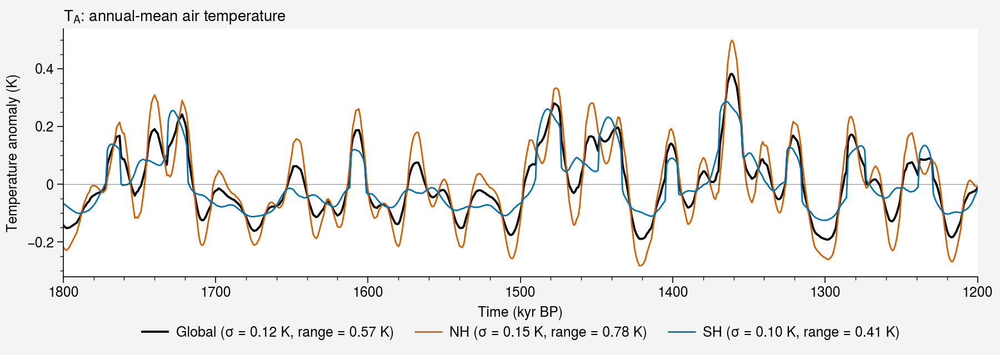

In [21]:
import numpy as np
import pandas as pd
import proplot as pplt

e = preMPT                                              # T_A
t = np.asarray(e.time)
REGIONS = {'Global': (-90, 90), 'NH': (0, 90), 'SH': (-90, 0)}
COLS    = {'Global': 'k', 'NH': '#D55E00', 'SH': '#0072B2'}

series, rows = {}, []
for name, (lmn, lmx) in REGIONS.items():
    x = np.asarray(e.Ta.band(lmn, lmx, when='annual', method='average'), float)
    series[name] = x
    rows.append({'Region': name,
                 'Mean (°C)':      x.mean() - 273.15,
                 'Std (K)':        x.std(ddof=1),
                 'Range (K)':      x.max() - x.min(),
                 'Min (°C)':       x.min() - 273.15,
                 'Max (°C)':       x.max() - 273.15,
                 'Max at (kyr BP)': t[np.argmax(x)],
                 'Min at (kyr BP)': t[np.argmin(x)]})

tab = pd.DataFrame(rows).set_index('Region')
print(tab.round(2).to_string())
print(tab.round(2).to_latex())                          # paste into the appendix if wanted

fig, ax = pplt.subplots(figsize=(9, 3.2))
for name, x in series.items():
    ax.plot(t, x - x.mean(), color=COLS[name], lw=1.4 if name == 'Global' else 1.0,
            label=f'{name} (σ = {x.std(ddof=1):.2f} K, range = {np.ptp(x):.2f} K)')
ax.axhline(0, color='k', lw=0.5, alpha=0.4)
ax.format(xreverse=True, xlabel='Time (kyr BP)', ylabel='Temperature anomaly (K)',
          title=r'$T_A$: annual-mean air temperature', titleloc='left', grid=False)
ax.legend(loc='b', ncols=3, frameon=False, prop={'size': 9})
ax.spines[['top', 'right']].set_visible(False)
fig.save('Ta_global_NH_SH.png', dpi=300)

In [24]:
x = preMPT.Ta.band(-90,90)
x.max() - x.min()

0.5733277146534927